In [1]:
import os
import re
import librosa
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats
import soundfile as sf
import shutil
from pathlib import Path
import random
from tqdm import tqdm
from scipy.optimize import curve_fit
import statsmodels.api as sm
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from scipy.stats import mannwhitneyu
from sklearn.metrics import silhouette_score
import wave
from scipy.io import wavfile
from scipy.signal import stft

In [2]:
base_dir = Path("data/new_sensors")

In [5]:
metadata_path = base_dir / "metadata_audio_hive22_30.csv"
features_path = base_dir / "features_audio_hive22_30_15s.csv"

skip_pipeline = features_path.exists()

if skip_pipeline:
    print({features_path})

    df_features = pd.read_csv(features_path)
    df_features["timestamp"] = pd.to_datetime(df_features["timestamp"])
    df_features["date"] = df_features["timestamp"].dt.date

    if "rms_dbfs" not in df_features.columns:
        print("Column rms_dbfs does not exist in the file. It will be added")
        df_features["rms_dbfs"] = np.where(
            df_features["rms"] > 0,
            20 * np.log10(df_features["rms"]),
            np.nan
        )

    print( df_features.shape)
else:
    print({features_path})

{PosixPath('data/new_sensors/features_audio_hive22_30_15s.csv')}
Column rms_dbfs does not exist in the file. It will be added
(9490, 21)


In [ ]:
if not skip_pipeline:
    for hive in range(22, 31):
        hive_dir = base_dir / str(hive)
        sensor_dirs = sorted(hive_dir.glob("sensor_*"))

        if not sensor_dirs:
            print(f"Hive {hive}: sensor folder not found.")
            continue

        if len(sensor_dirs) > 1:
            print(
                f"Hive {hive}: found {len(sensor_dirs)} sensor folders; "
            )
            continue

        source_dir = sensor_dirs[0]
        dest_dir = hive_dir / f"all_audio_hive{hive}"
        dest_dir.mkdir(parents=True, exist_ok=True)

        audio_files = [
            file_path for file_path in source_dir.rglob("*.wav")
            if dest_dir not in file_path.parents
        ]

        print(
            f"Hive {hive}: sensor={source_dir.name}, "
            f"number of recordings={len(audio_files)}"
        )

        moved_count = 0
        skipped_count = 0

        for file_path in tqdm(
            audio_files,
            desc=f"Hive {hive}",
            unit="file"
        ):
            destination = dest_dir / file_path.name

            if destination.exists():
                skipped_count += 1
                continue

            try:
                shutil.move(str(file_path), str(destination))
                moved_count += 1
            except Exception as error:
                print(f"Error while moving {file_path}: {error}")

        print(
            f"Hive {hive}: moved {moved_count} files, "
            f"skipped {skipped_count}."
        )

In [ ]:
if not skip_pipeline:
    records = []
    errors = []

    timestamp_pattern = re.compile(
        r"(?P<timestamp>20\d{2}-\d{2}-\d{2}_\d{2}-\d{2}-\d{2})"
    )
    duration_pattern = re.compile(r"_(?P<duration>\d+(?:\.\d+)?)s$")

    for hive in range(22, 31):
        audio_dir = base_dir / str(hive) / f"all_audio_hive{hive}"
        audio_files = sorted(audio_dir.glob("*.wav"))

        for file_path in tqdm(
            audio_files,
            desc=f"Hive {hive}",
            unit="file"
        ):
            try:
                with wave.open(str(file_path), "rb") as wav:
                    channels = wav.getnchannels()
                    sample_rate = wav.getframerate()
                    sample_width = wav.getsampwidth()
                    n_frames = wav.getnframes()

                if sample_rate <= 0:
                    raise ValueError("Invalid sampling rate.")

                timestamp_match = timestamp_pattern.search(file_path.stem)
                if timestamp_match is None:
                    raise ValueError(
                        "Timestamp not recognised in the file name."
                    )

                timestamp = pd.to_datetime(
                    timestamp_match.group("timestamp"),
                    format="%Y-%m-%d_%H-%M-%S",
                    errors="raise"
                )

                duration = n_frames / sample_rate
                duration_match = duration_pattern.search(file_path.stem)
                filename_duration = (
                    float(duration_match.group("duration"))
                    if duration_match is not None
                    else np.nan
                )

                records.append({
                    "hive": hive,
                    "filename": file_path.name,
                    "timestamp": timestamp,
                    "sample_rate": sample_rate,
                    "channels": channels,
                    "sample_width": sample_width,
                    "n_frames": n_frames,
                    "duration_s": duration,
                    "filename_duration_s": filename_duration
                })

            except Exception as error:
                errors.append({
                    "hive": hive,
                    "filename": file_path.name,
                    "error": str(error)
                })


    df_metadata = pd.DataFrame(records)
    df_errors = pd.DataFrame(errors)

In [ ]:
if not skip_pipeline:
    print("Number of correctly read files:", len(df_metadata))
    print("Number of errors:", len(df_errors))

    print("\nSampling rates:")
    print(df_metadata["sample_rate"].value_counts().sort_index())

    print("\nNumber of channels:")
    print(df_metadata["channels"].value_counts().sort_index())

    print("\nRecording length:")
    print(df_metadata["duration_s"].describe())

In [ ]:
if not skip_pipeline:
    files_per_hive = (
        df_metadata
        .groupby("hive")
        .size()
        .rename("n_files")
    )

    print(files_per_hive)

In [ ]:
if not skip_pipeline:
    df_metadata["date"] = df_metadata["timestamp"].dt.date

    files_per_day = (
        df_metadata
        .groupby(["hive", "date"])
        .size()
        .unstack(fill_value=0)
    )

    print(files_per_day)

In [ ]:
if not skip_pipeline:
    df_metadata = df_metadata.sort_values(
        ["hive", "timestamp"]
    ).copy()

    df_metadata["interval_s"] = (
        df_metadata
        .groupby("hive")["timestamp"]
        .diff()
        .dt.total_seconds()
    )

    print(
        df_metadata["interval_s"]
        .describe()
    )

In [ ]:
if not skip_pipeline:
    gaps = df_metadata[
        df_metadata["interval_s"] > 90
    ].copy()

    print("Number of gaps > 90 s:", len(gaps))

In [ ]:
if not skip_pipeline:
    duplicates_or_short = df_metadata[
        df_metadata["interval_s"] < 30
    ].copy()

    print("Number of gaps < 30 s:", len(duplicates_or_short))

In [ ]:
if not skip_pipeline:
    df_metadata["filename_duration_s"] = pd.to_numeric(
        df_metadata["filename_duration_s"],
        errors="coerce"
    )

    df_metadata["duration_difference_s"] = (
        df_metadata["duration_s"]
        - df_metadata["filename_duration_s"]
    )

    print(
        df_metadata["duration_difference_s"].describe()
    )

In [ ]:
if not skip_pipeline:
    metadata_path = base_dir / "metadata_audio_hive22_30.csv"

    df_metadata.to_csv(
        metadata_path,
        index=False
    )

    print(metadata_path)

In [ ]:
if not skip_pipeline:
    duration_counts = (
        df_metadata["duration_s"]
        .round(3)
        .value_counts()
        .sort_index()
    )

    print(duration_counts)

In [ ]:
if not skip_pipeline:
    long_recordings = df_metadata[
        df_metadata["duration_s"] > 30
    ].copy()

    print("Number of recordings > 30 s:", len(long_recordings))

    print(
        long_recordings[
            ["hive", "date", "timestamp", "filename", "duration_s"]
        ].to_string(index=False)
    )

In [ ]:
if not skip_pipeline:
    long_recordings = df_metadata[
        df_metadata["duration_s"] > 30
    ].copy()

    transition = (
        long_recordings
        .groupby(["hive", "date"])
        .agg(
            n_long=("duration_s", "size"),
            first_long=("timestamp", "min"),
            last_long=("timestamp", "max"),
            mean_duration=("duration_s", "mean")
        )
        .reset_index()
    )

    print(transition.to_string(index=False))

In [ ]:
if not skip_pipeline:
    short_recordings = df_metadata[
        df_metadata["duration_s"] <= 30
    ].copy()

    short_summary = (
        short_recordings
        .groupby(["hive", "date"])
        .agg(
            n_short=("duration_s", "size"),
            first_short=("timestamp", "min"),
            last_short=("timestamp", "max")
        )).reset_index()

    print(short_summary.to_string(index=False))

In [ ]:
if not skip_pipeline:
    df_metadata["recording_mode"] = "15s"

    df_metadata.loc[
        df_metadata["duration_s"] > 30,
        "recording_mode"
    ] = "60s"

In [ ]:
if not skip_pipeline:
    print(
        df_metadata["recording_mode"].value_counts()
    )

In [ ]:
if not skip_pipeline:
    df_analysis = df_metadata[
        df_metadata["recording_mode"] == "15s"
    ].copy()

In [ ]:
if not skip_pipeline:
    print(
        df_analysis
        .groupby("hive")
        .size()
    )

In [ ]:
if not skip_pipeline:
    print(
        df_analysis
        .groupby(["hive", "date"])
        .size()
        .unstack(fill_value=0)
    )

In [ ]:
if not skip_pipeline:
    df_features = df_analysis.copy()

In [ ]:
if not skip_pipeline:
    df_features = df_features[
        df_features["recording_mode"] == "15s"
    ].copy()

In [ ]:
if not skip_pipeline:
    df_features = df_features.sort_values(
        ["hive", "timestamp"]
    ).reset_index(drop=True)

In [ ]:
if not skip_pipeline:
    def normalize_audio(y):
        """
        Normalisation of the audio signal to a range of about [-1, 1].
        """
        if np.issubdtype(y.dtype, np.integer):
            info = np.iinfo(y.dtype)
            scale = max(abs(info.min), info.max)
            y = y.astype(np.float32) / scale

        elif np.issubdtype(y.dtype, np.floating):
            y = y.astype(np.float32)

        else:
            y = y.astype(np.float32)

        return y

In [ ]:
if not skip_pipeline:
    def extract_features(file_path):
        """
        Extraction of basic time and frequency features
        from a single WAV recording.
        """

        sample_rate, y = wavfile.read(file_path)

        y = normalize_audio(y)

        if y.ndim > 1:
            y = np.mean(y, axis=1)

        y = y - np.mean(y)


        rms = np.sqrt(np.mean(y ** 2))

        peak = np.max(np.abs(y))

        if rms > 0:
            crest_factor = peak / rms
        else:
            crest_factor = np.nan

        zero_crossings = np.sum(
            y[:-1] * y[1:] < 0
        )

        zcr = zero_crossings / len(y)



        frequencies, times, Zxx = stft(
            y,
            fs=sample_rate,
            window="hann",
            nperseg=2048,
            noverlap=1024,
            boundary=None
        )

        magnitude = np.abs(Zxx)

        power = np.mean(magnitude ** 2, axis=1)

        total_power = np.sum(power)

        if total_power == 0:
            return {
                "sample_rate": sample_rate,
                "n_samples": len(y),
                "duration_s_calculated": len(y) / sample_rate,
                "rms": rms,
                "peak": peak,
                "crest_factor": crest_factor,
                "zero_crossing_rate": zcr,
                "spectral_centroid": np.nan,
                "spectral_bandwidth": np.nan,
                "spectral_rolloff": np.nan,
                "spectral_flatness": np.nan,
                "band_0_500": np.nan,
                "band_500_1000": np.nan,
                "band_1000_2000": np.nan,
                "band_2000_4000": np.nan,
                "band_4000_8000": np.nan,
            }


        spectral_centroid = (
            np.sum(frequencies * power) / total_power
        )


        spectral_bandwidth = np.sqrt(
            np.sum(
                ((frequencies - spectral_centroid) ** 2) * power
            ) / total_power
        )


        cumulative_power = np.cumsum(power)

        rolloff_threshold = 0.85 * total_power

        rolloff_idx = np.searchsorted(
            cumulative_power,
            rolloff_threshold
        )

        rolloff_idx = min(
            rolloff_idx,
            len(frequencies) - 1
        )

        spectral_rolloff = frequencies[rolloff_idx]


        positive_power = power[power > 0]

        geometric_mean = np.exp(
            np.mean(np.log(positive_power))
        )

        arithmetic_mean = np.mean(positive_power)

        spectral_flatness = (
            geometric_mean / arithmetic_mean
            if arithmetic_mean > 0
            else np.nan
        )

        bands = {
            "band_0_500": (0, 500),
            "band_500_1000": (500, 1000),
            "band_1000_2000": (1000, 2000),
            "band_2000_4000": (2000, 4000),
            "band_4000_8000": (4000, 8000),
        }

        band_features = {}

        for name, (low, high) in bands.items():

            mask = (
                (frequencies >= low)
                & (frequencies < high)
            )

            band_power = np.sum(power[mask])

            band_features[name] = (
                band_power / total_power
            )

        return {
            "sample_rate": sample_rate,
            "n_samples": len(y),
            "duration_s_calculated": len(y) / sample_rate,
            "rms": rms,
            "peak": peak,
            "crest_factor": crest_factor,
            "zero_crossing_rate": zcr,
            "spectral_centroid": spectral_centroid,
            "spectral_bandwidth": spectral_bandwidth,
            "spectral_rolloff": spectral_rolloff,
            "spectral_flatness": spectral_flatness,
            **band_features,
        }

In [ ]:
if not skip_pipeline:
    feature_records = []
    feature_errors = []

    for row in tqdm(
        df_features.itertuples(index=False),
        total=len(df_features),
        desc="Feature extraction",
        unit="file"
    ):

        file_path = (
            base_dir
            / str(row.hive)
            / f"all_audio_hive{row.hive}"
            / row.filename
        )

        try:

            features = extract_features(file_path)

            record = {
                "hive": row.hive,
                "date": row.date,
                "timestamp": row.timestamp,
                "filename": row.filename,
                **features
            }

            feature_records.append(record)

        except Exception as e:

            feature_errors.append({
                "hive": row.hive,
                "timestamp": row.timestamp,
                "filename": row.filename,
                "error": str(e)
            })

In [ ]:
if not skip_pipeline:
    df_features = pd.DataFrame(feature_records)
    df_feature_errors = pd.DataFrame(feature_errors)

    print("Number of processed recordings:", len(df_features))
    print("Number of errors:", len(df_feature_errors))

In [ ]:
if not skip_pipeline:
    # RMS in decibels (dBFS), same as in audio_analysis.ipynb
    df_features["rms_dbfs"] = np.where(
        df_features["rms"] > 0,
        20 * np.log10(df_features["rms"]),
        np.nan
    )

In [ ]:
if not skip_pipeline:
    features_path = base_dir / "features_audio_hive22_30_15s.csv"

    df_features.to_csv(
        features_path,
        index=False
    )

    print({features_path})

In [6]:
print(
    df_features[
        [
            "rms_dbfs",
            "peak",
            "crest_factor",
            "zero_crossing_rate",
            "spectral_centroid",
            "spectral_bandwidth",
            "spectral_rolloff",
            "spectral_flatness",
            "band_0_500",
            "band_500_1000",
            "band_1000_2000",
            "band_2000_4000",
            "band_4000_8000"
        ]
    ].describe().T
)

                     count        mean          std         min         25%  \
rms_dbfs            9490.0  -26.776560     4.760217  -40.478513  -29.827430   
peak                9490.0    0.333894     0.226350    0.066346    0.191161   
crest_factor        9490.0    6.913501     4.237382    1.237626    4.454651   
zero_crossing_rate  9490.0    0.080661     0.038030    0.017407    0.054407   
spectral_centroid   9490.0  547.354424   508.581307  120.663267  286.659775   
spectral_bandwidth  9490.0  986.304082   662.847628  172.014479  511.970484   
spectral_rolloff    9490.0  893.936051  1520.802911  117.187500  335.937500   
spectral_flatness   9490.0    0.049637     0.045114    0.002405    0.019042   
band_0_500          9490.0    0.868909     0.104808    0.179492    0.851521   
band_500_1000       9490.0    0.068027     0.044350    0.003912    0.042941   
band_1000_2000      9490.0    0.008690     0.011439    0.000351    0.003154   
band_2000_4000      9490.0    0.010787     0.038592 

In [7]:
print(
    df_features.isna().sum()
)

hive                     0
date                     0
timestamp                0
filename                 0
sample_rate              0
n_samples                0
duration_s_calculated    0
rms                      0
peak                     0
crest_factor             0
zero_crossing_rate       0
spectral_centroid        0
spectral_bandwidth       0
spectral_rolloff         0
spectral_flatness        0
band_0_500               0
band_500_1000            0
band_1000_2000           0
band_2000_4000           0
band_4000_8000           0
rms_dbfs                 0
dtype: int64


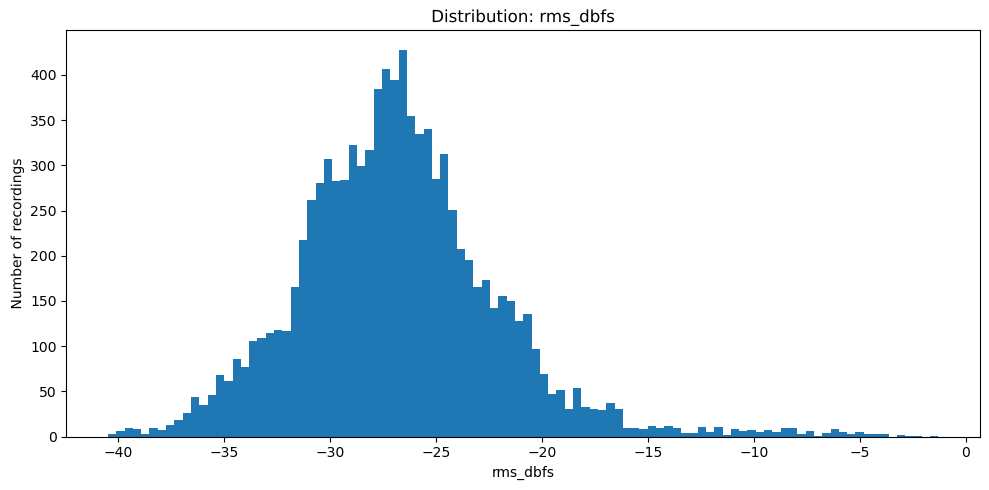

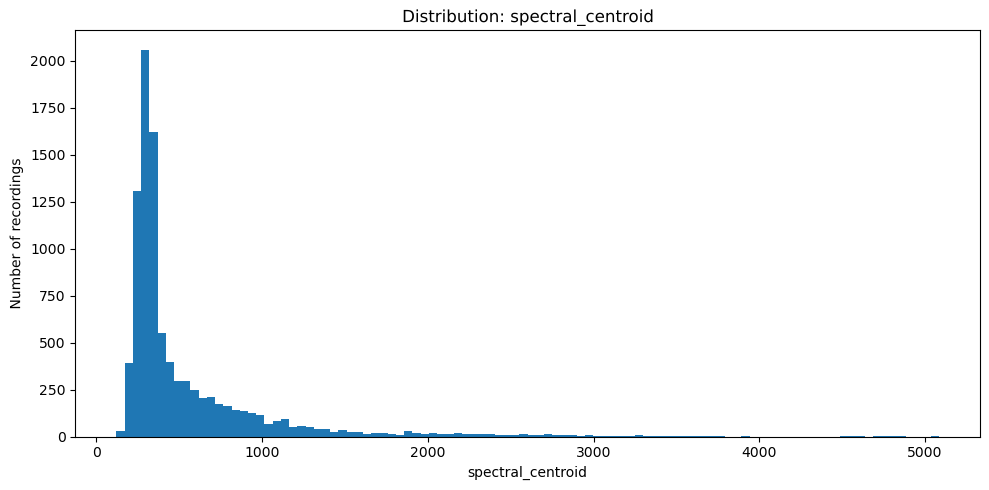

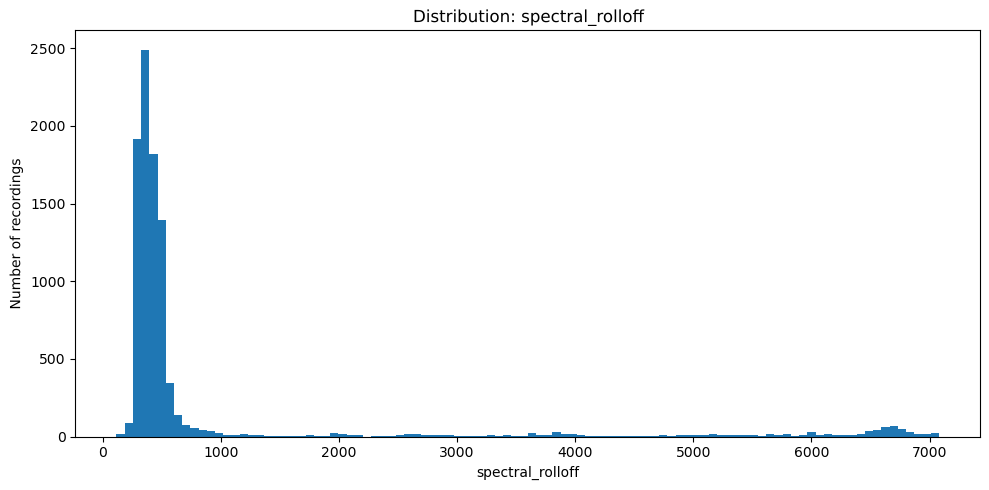

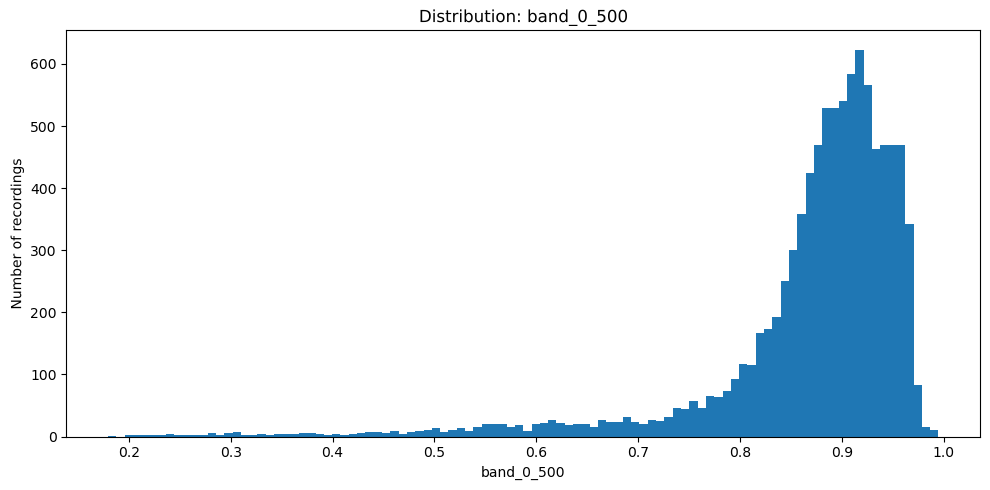

In [8]:
features_to_plot = [
    "rms_dbfs",
    "spectral_centroid",
    "spectral_rolloff",
    "band_0_500"
]

for feature in features_to_plot:

    plt.figure(figsize=(10, 5))

    plt.hist(
        df_features[feature],
        bins=100
    )

    plt.xlabel(feature)
    plt.ylabel("Number of recordings")
    plt.title(f"Distribution: {feature}")

    plt.tight_layout()
    plt.show()

<Figure size 1200x600 with 0 Axes>

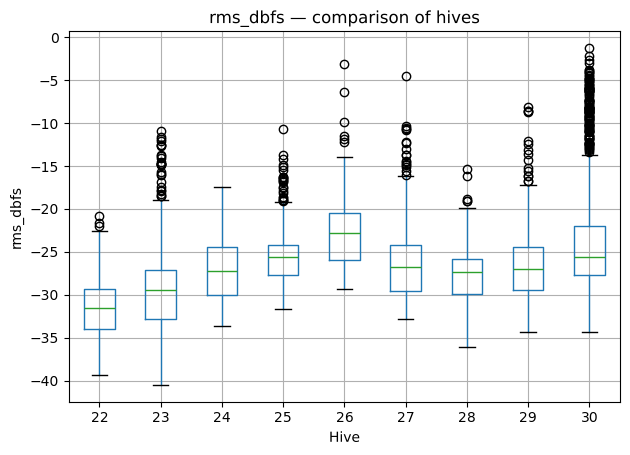

<Figure size 1200x600 with 0 Axes>

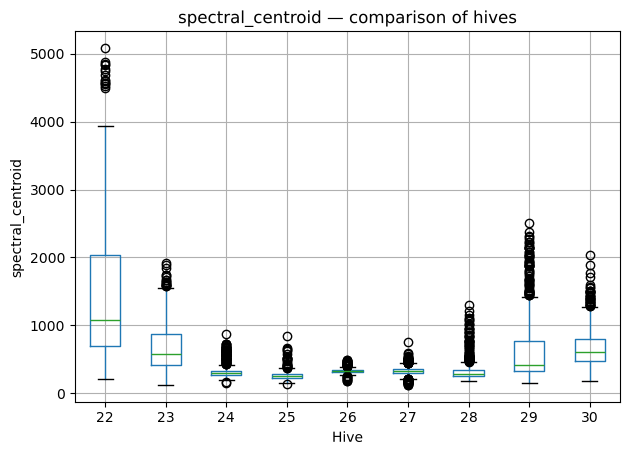

<Figure size 1200x600 with 0 Axes>

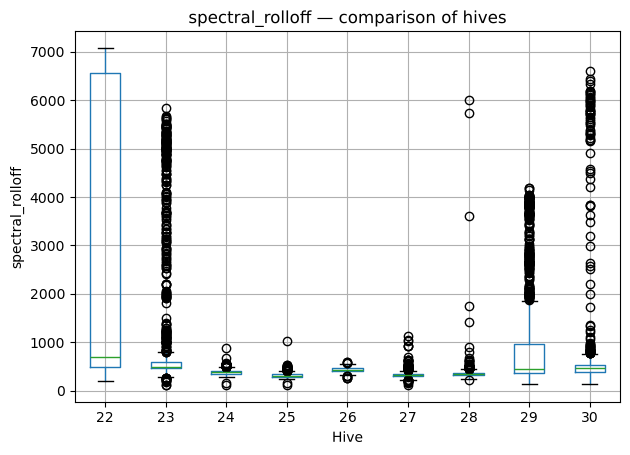

<Figure size 1200x600 with 0 Axes>

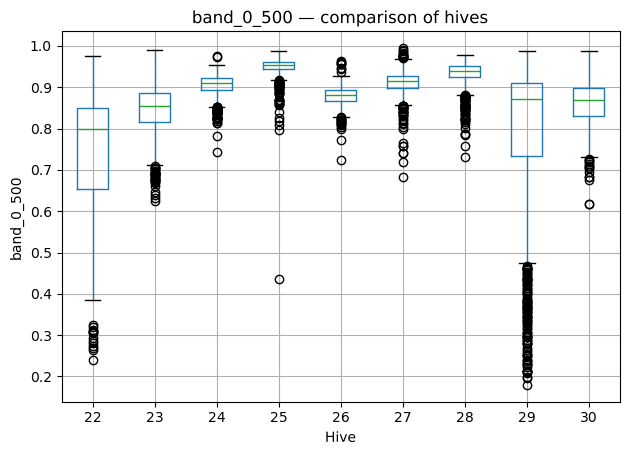

In [9]:
for feature in features_to_plot:

    plt.figure(figsize=(12, 6))

    df_features.boxplot(
        column=feature,
        by="hive"
    )

    plt.title(f"{feature} — comparison of hives")
    plt.suptitle("")
    plt.xlabel("Hive")
    plt.ylabel(feature)

    plt.tight_layout()
    plt.show()

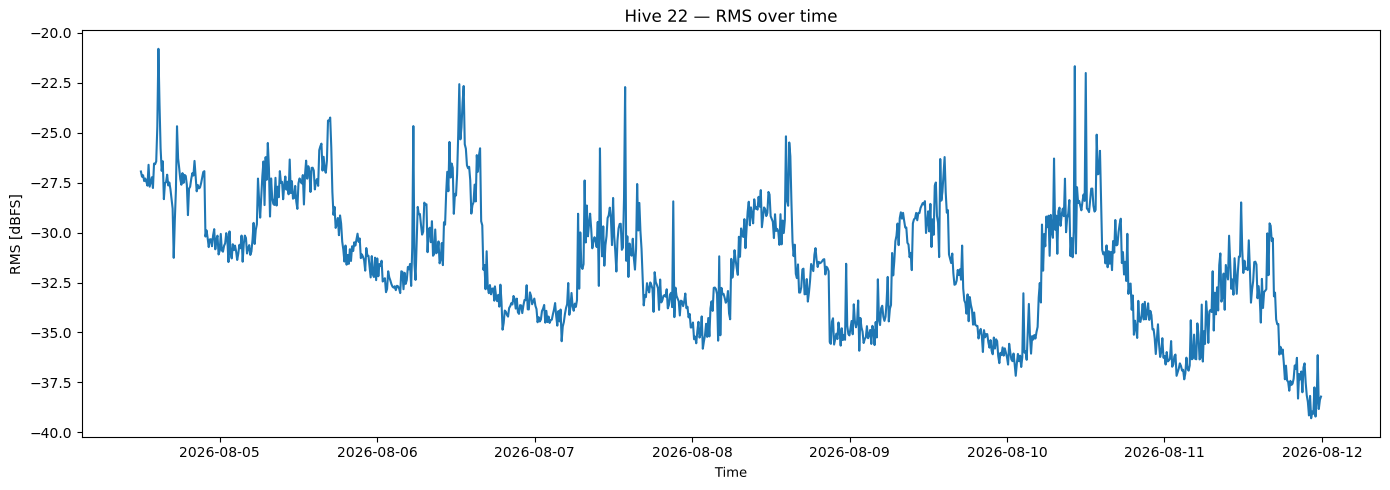

In [10]:
hive_22 = df_features[
    df_features["hive"] == 22
].copy()

plt.figure(figsize=(14, 5))

plt.plot(
    hive_22["timestamp"],
    hive_22["rms_dbfs"]
)

plt.xlabel("Time")
plt.ylabel("RMS [dBFS]")
plt.title("Hive 22 — RMS over time")

plt.tight_layout()
plt.show()

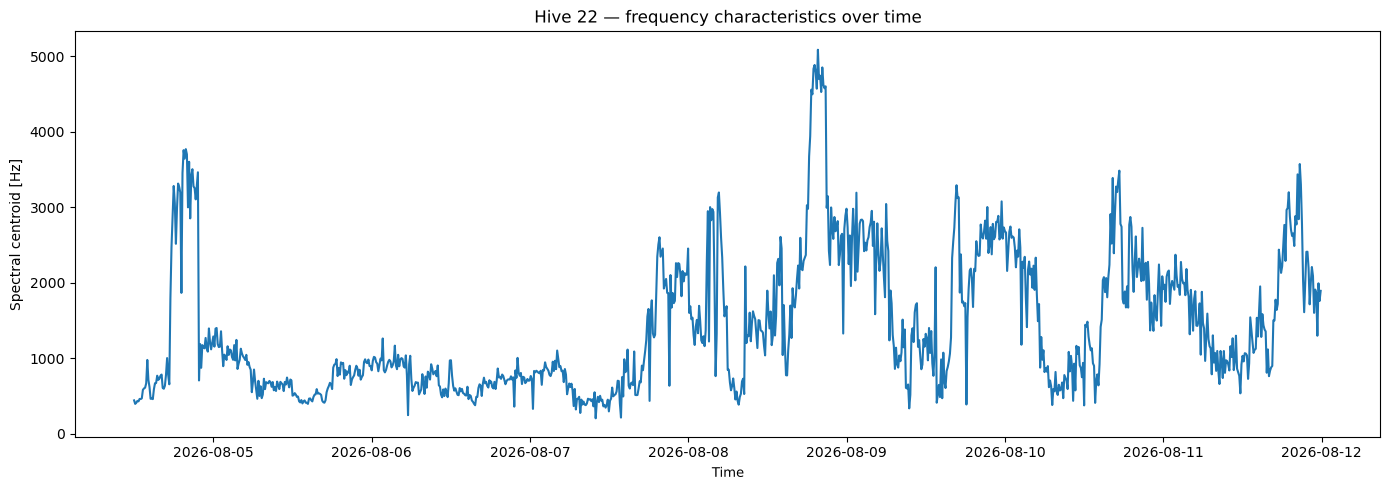

In [11]:
plt.figure(figsize=(14, 5))

plt.plot(
    hive_22["timestamp"],
    hive_22["spectral_centroid"]
)

plt.xlabel("Time")
plt.ylabel("Spectral centroid [Hz]")
plt.title("Hive 22 — frequency characteristics over time")

plt.tight_layout()
plt.show()

In [12]:
features = [
    "rms_dbfs",
    "peak",
    "crest_factor",
    "zero_crossing_rate",
    "spectral_centroid",
    "spectral_bandwidth",
    "spectral_rolloff",
    "spectral_flatness",
    "band_0_500",
    "band_500_1000",
    "band_1000_2000",
    "band_2000_4000",
    "band_4000_8000"
]

hive_summary = (
    df_features
    .groupby("hive")[features]
    .agg(["mean", "median", "std", "min", "max"])
    .round(4)
)

print(hive_summary.to_string())

     rms_dbfs                                       peak                                 crest_factor                                  zero_crossing_rate                                 spectral_centroid                                           spectral_bandwidth                                           spectral_rolloff                                           spectral_flatness                                 band_0_500                                 band_500_1000                                 band_1000_2000                                 band_2000_4000                                 band_4000_8000                                
         mean   median     std      min      max    mean  median     std     min     max         mean  median     std     min      max               mean  median     std     min     max              mean     median       std       min        max               mean     median       std       min        max             mean    median        std       min

In [13]:
check_features = [
    "rms_dbfs",
    "spectral_centroid",
    "spectral_rolloff",
    "band_0_500",
    "band_4000_8000"
]

percentiles = [0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]

for feature in check_features:

    result = (
        df_features
        .groupby("hive")[feature]
        .quantile(percentiles)
        .unstack()
        .round(4)
    )

    print(f"\n{feature}")
    print(result.to_string())


rms_dbfs
         0.01     0.05     0.25     0.50     0.75     0.95     0.99
hive                                                               
22   -38.1795 -36.4569 -33.9334 -31.5761 -29.2747 -26.7133 -24.6251
23   -39.5677 -36.5394 -32.7852 -29.4019 -27.1300 -21.6196 -14.6924
24   -33.0194 -31.6770 -30.0355 -27.2279 -24.4400 -21.3430 -19.1014
25   -30.8103 -29.6476 -27.6486 -25.6481 -24.2143 -20.5762 -16.6786
26   -28.5908 -27.8244 -25.9843 -22.7768 -20.4775 -17.3235 -16.0757
27   -32.0972 -31.4339 -29.5747 -26.7062 -24.2072 -18.3940 -13.6715
28   -35.1309 -32.7605 -29.9567 -27.3341 -25.7762 -22.6828 -20.8503
29   -33.3097 -31.5364 -29.4251 -26.9939 -24.4085 -20.3253 -16.0665
30   -33.2982 -30.2741 -27.6419 -25.6194 -21.9906  -8.3167  -4.6684

spectral_centroid
          0.01      0.05      0.25       0.50       0.75       0.95       0.99
hive                                                                          
22    363.5622  441.9275  700.8142  1072.1504  2030.5650  3002.42

In [14]:
extreme_features = [
    "rms_dbfs",
    "spectral_centroid",
    "spectral_rolloff",
    "band_4000_8000"
]

for feature in extreme_features:

    print(f"\n {feature}")

    top = (
        df_features
        .nlargest(10, feature)
        [
            [
                "hive",
                "timestamp",
                "filename",
                feature
            ]
        ]
    )

    print(top.to_string(index=False))


 rms_dbfs
 hive           timestamp                        filename  rms_dbfs
   30 2026-08-10 16:10:15 2026-08-10_16-10-15_14.592s.wav -1.283358
   30 2026-08-10 10:20:01 2026-08-10_10-20-01_14.592s.wav -2.210204
   30 2026-08-05 08:39:58 2026-08-05_08-39-58_14.592s.wav -2.693712
   30 2026-08-04 14:19:15 2026-08-04_14-19-15_14.592s.wav -3.042091
   26 2026-08-09 14:59:25 2026-08-09_14-59-25_14.592s.wav -3.178994
   30 2026-08-10 10:50:03 2026-08-10_10-50-03_14.592s.wav -3.780580
   30 2026-08-06 10:30:58 2026-08-06_10-30-58_14.592s.wav -3.780988
   30 2026-08-04 16:09:19 2026-08-04_16-09-19_13.824s.wav -4.001057
   30 2026-08-09 10:19:06 2026-08-09_10-19-06_14.592s.wav -4.049610
   30 2026-08-10 11:00:03 2026-08-10_11-00-03_14.592s.wav -4.204032

 spectral_centroid
 hive           timestamp                        filename  spectral_centroid
   22 2026-08-08 19:38:40 2026-08-08_19-38-40_13.824s.wav        5083.064816
   22 2026-08-08 19:08:39 2026-08-08_19-08-39_13.824s.wav        48

In [15]:
df_features["hour_decimal"] = (
    df_features["timestamp"].dt.hour
    + df_features["timestamp"].dt.minute / 60
)

mask = (
    (df_features["date"] == pd.Timestamp("2026-08-08").date())
    & (df_features["hour_decimal"] >= 18.5)
    & (df_features["hour_decimal"] <= 21.0)
)

episode = df_features.loc[
    mask,
    [
        "hive",
        "timestamp",
        "rms_dbfs",
        "spectral_centroid",
        "spectral_rolloff",
        "band_0_500",
        "band_4000_8000"
    ]
]

print(
    episode
    .groupby("hive")
    .agg(
        n=("rms_dbfs", "count"),
        rms_median=("rms_dbfs", "median"),
        rms_mean=("rms_dbfs", "mean"),
        centroid_median=("spectral_centroid", "median"),
        centroid_mean=("spectral_centroid", "mean"),
        rolloff_median=("spectral_rolloff", "median"),
        rolloff_mean=("spectral_rolloff", "mean"),
        low_band_median=("band_0_500", "median"),
        high_band_median=("band_4000_8000", "median"),
    )
    .round(4)
    .to_string()
)

       n  rms_median  rms_mean  centroid_median  centroid_mean  rolloff_median  rolloff_mean  low_band_median  high_band_median
hive                                                                                                                           
22    15    -31.5056  -31.7753        4618.2509      4585.4370       7039.0625     7029.1667           0.3048            0.6661
23    15    -33.1803  -32.9801         981.3301       984.3493       1195.3125     2075.5208           0.7893            0.1154
24    15    -30.2255  -30.1983         290.5338       280.2086        367.1875      369.7917           0.9096            0.0083
25    15    -28.1616  -28.2993         226.1886       226.7738        289.0625      289.5833           0.9601            0.0041
26    15    -26.0207  -25.9883         324.5980       323.5678        421.8750      423.9583           0.8799            0.0037
27    15    -30.8246  -30.4693         303.5765       307.7961        304.6875      317.1875           0

In [16]:
hive22 = df_features[
    df_features["hive"] == 22
].copy()

periods = {
    "before": (
        "2026-08-08 16:00",
        "2026-08-08 18:30"
    ),
    "episode": (
        "2026-08-08 18:40",
        "2026-08-08 21:00"
    ),
    "after": (
        "2026-08-08 21:10",
        "2026-08-08 23:30"
    )
}

rows = []

for period, (start, end) in periods.items():

    subset = hive22[
        (hive22["timestamp"] >= start)
        & (hive22["timestamp"] <= end)
    ]

    rows.append({
        "period": period,
        "n": len(subset),
        "rms_median": subset["rms_dbfs"].median(),
        "rms_mean": subset["rms_dbfs"].mean(),
        "centroid_median": subset["spectral_centroid"].median(),
        "centroid_mean": subset["spectral_centroid"].mean(),
        "rolloff_median": subset["spectral_rolloff"].median(),
        "rolloff_mean": subset["spectral_rolloff"].mean(),
        "band_0_500_median": subset["band_0_500"].median(),
        "band_4000_8000_median": subset["band_4000_8000"].median(),
    })

episode_comparison = pd.DataFrame(rows)

print(
    episode_comparison
    .round(4)
    .to_string(index=False)
)

 period  n  rms_median  rms_mean  centroid_median  centroid_mean  rolloff_median  rolloff_mean  band_0_500_median  band_4000_8000_median
 before 15    -32.4238  -32.4413        2288.5411      2483.1715       6757.8125     6785.4167             0.6235                 0.3102
episode 14    -31.5208  -31.8228        4656.6258      4587.6357       7042.9688     7029.5759             0.2995                 0.6713
  after 14    -35.0896  -34.8151        2634.6191      2517.3665       6714.8438     6648.9955             0.5790                 0.3763


In [17]:
features = [
    "rms_dbfs",
    "spectral_centroid",
    "band_0_500",
    "band_4000_8000"
]

df_features = df_features.sort_values(["hive", "timestamp"]).copy()

for feature in features:
    median = df_features.groupby("hive")[feature].transform("median")

    mad = df_features.groupby("hive")[feature].transform(
        lambda x: (x - x.median()).abs().median()
    )

    mad = mad.replace(0, np.nan)

    df_features[f"{feature}_z"] = (
        df_features[feature] - median
    ) / (1.4826 * mad)

print(
    df_features[
        [
            "hive",
            "timestamp",
            "rms_dbfs_z",
            "spectral_centroid_z",
            "band_0_500_z",
            "band_4000_8000_z"
        ]
    ].describe()
)

              hive                      timestamp   rms_dbfs_z  \
count  9490.000000                           9490  9490.000000   
mean     25.976185  2026-08-08 04:13:16.154899968     0.068378   
min      22.000000            2026-08-04 11:58:53    -2.947748   
25%      24.000000  2026-08-06 07:50:47.249999872    -0.705162   
50%      26.000000     2026-08-08 03:48:02.500000     0.000000   
75%      28.000000            2026-08-09 23:49:36     0.635961   
max      30.000000            2026-08-11 23:51:48     6.470443   
std       2.608437                            NaN     1.105167   

       spectral_centroid_z  band_0_500_z  band_4000_8000_z  
count          9490.000000   9490.000000       9490.000000  
mean              0.389796     -0.334211          0.531031  
min              -5.805838    -39.885855         -2.169644  
25%              -0.572454     -0.835205         -0.561284  
50%               0.000000      0.000000          0.000000  
75%               0.889036      0.58186

In [18]:
thresholds = [2, 2.5, 3, 4]

for threshold in thresholds:
    mask = (
        (df_features["spectral_centroid_z"] > threshold) &
        (df_features["band_4000_8000_z"] > threshold) &
        (df_features["band_0_500_z"] < -1)
    )

    print(
        f"threshold {threshold}: {mask.sum()} recordings "
        f"({mask.mean() * 100:.2f}%)"
    )

threshold 2: 810 recordings (8.54%)
threshold 2.5: 564 recordings (5.94%)
threshold 3: 410 recordings (4.32%)
threshold 4: 241 recordings (2.54%)


In [19]:
df_features["high_freq_anomaly"] = (
    (df_features["spectral_centroid_z"] > 3) &
    (df_features["band_4000_8000_z"] > 3) &
    (df_features["band_0_500_z"] < -1)
)

In [20]:
df_features["time_diff_min"] = (
    df_features.groupby("hive")["timestamp"]
    .diff()
    .dt.total_seconds() / 60
)

df_features["new_episode"] = (
    df_features["time_diff_min"].isna()
    | (df_features["time_diff_min"] > 20)
    | (~df_features["high_freq_anomaly"])
)

df_features["episode_id"] = (
    df_features.groupby("hive")["new_episode"]
    .cumsum()
)

In [21]:
episodes = (
    df_features[df_features["high_freq_anomaly"]]
    .groupby(["hive", "episode_id"])
    .agg(
        n=("timestamp", "size"),
        start=("timestamp", "min"),
        end=("timestamp", "max"),
        rms_median=("rms_dbfs", "median"),
        centroid_median=("spectral_centroid", "median"),
        low_band_median=("band_0_500", "median"),
        high_band_median=("band_4000_8000", "median")
    )
    .reset_index()
)

episodes["duration_min"] = (
    episodes["end"] - episodes["start"]
).dt.total_seconds() / 60

episodes = episodes.sort_values(
    ["n", "duration_min"],
    ascending=False
)

In [22]:
episodes_long = episodes[episodes["n"] >= 3].copy()

print(
    episodes_long[
        [
            "hive",
            "start",
            "end",
            "n",
            "duration_min",
            "rms_median",
            "centroid_median",
            "low_band_median",
            "high_band_median"
        ]
    ].to_string(index=False)
)

 hive               start                 end  n  duration_min  rms_median  centroid_median  low_band_median  high_band_median
   24 2026-08-11 01:50:57 2026-08-11 11:31:19 59    580.366667  -30.389338       604.508557         0.849237          0.052857
   22 2026-08-08 18:18:37 2026-08-08 20:48:42 16    150.083333  -31.520821      4608.723645         0.306124          0.664340
   29 2026-08-08 15:18:30 2026-08-08 17:38:36 15    140.100000  -24.912231      1946.961044         0.458693          0.064602
   29 2026-08-08 18:18:37 2026-08-08 20:38:43 15    140.100000  -27.370293      2056.197006         0.398774          0.083555
   29 2026-08-08 20:58:43 2026-08-08 22:48:48 12    110.083333  -28.857474      1366.217912         0.605271          0.138745
   29 2026-08-09 14:59:25 2026-08-09 16:39:29 11    100.066667  -24.954479      1136.122670         0.592735          0.063052
   28 2026-08-11 15:11:04 2026-08-11 16:41:07 10     90.050000  -31.688608       554.312153         0.851013   

In [23]:
episodes_check = (
    df_features[df_features["high_freq_anomaly"]]
    .groupby(["hive", "episode_id"])
    .agg(
        n=("timestamp", "size"),
        start=("timestamp", "min"),
        end=("timestamp", "max"),

        rms_median=("rms_dbfs", "median"),
        rms_mean=("rms_dbfs", "mean"),

        centroid_median=("spectral_centroid", "median"),
        centroid_mean=("spectral_centroid", "mean"),

        rolloff_median=("spectral_rolloff", "median"),

        low_band_median=("band_0_500", "median"),
        high_band_median=("band_4000_8000", "median")
    )
    .reset_index()
)

episodes_check["duration_min"] = (
    episodes_check["end"] - episodes_check["start"]
).dt.total_seconds() / 60

episodes_check["start_hour"] = (
    episodes_check["start"].dt.hour
    + episodes_check["start"].dt.minute / 60
)

episodes_check = episodes_check.sort_values(
    ["hive", "start"]
)

print(
    episodes_check[
        [
            "hive",
            "start",
            "end",
            "n",
            "duration_min",
            "start_hour",
            "rms_median",
            "centroid_median",
            "rolloff_median",
            "low_band_median",
            "high_band_median"
        ]
    ].to_string(index=False)
)

 hive               start                 end  n  duration_min  start_hour  rms_median  centroid_median  rolloff_median  low_band_median  high_band_median
   22 2026-08-04 19:19:18 2026-08-04 19:59:20  5     40.033333   19.316667  -27.321960      3699.053668      6992.18750         0.426612          0.521778
   22 2026-08-04 20:19:21 2026-08-04 20:19:21  1      0.000000   20.316667  -27.157082      3600.005437      7015.62500         0.441428          0.505103
   22 2026-08-04 20:39:22 2026-08-04 20:49:22  2     10.000000   20.650000  -27.709190      3463.160712      7000.00000         0.446189          0.482653
   22 2026-08-04 21:39:24 2026-08-04 21:39:24  1      0.000000   21.650000  -26.932315      3461.402570      6976.56250         0.449501          0.484450
   22 2026-08-08 18:18:37 2026-08-08 20:48:42 16    150.083333   18.300000  -31.520821      4608.723645      7039.06250         0.306124          0.664340
   22 2026-08-10 16:20:24 2026-08-10 16:20:24  1      0.000000   16.33

In [24]:
print(
    episodes_check.groupby("hive").agg(
        n_episodes=("episode_id", "size"),
        total_anomaly_samples=("n", "sum"),
        median_duration_min=("duration_min", "median"),
        max_duration_min=("duration_min", "max"),
        median_centroid=("centroid_median", "median"),
        median_high_band=("high_band_median", "median")
    ).round(2)
)

      n_episodes  total_anomaly_samples  median_duration_min  \
hive                                                           
22             9                     31                10.00   
23            21                     27                 0.00   
24             8                     72                 0.00   
25            11                     21                 0.00   
26            10                     13                 0.00   
27            17                     28                 0.00   
28            36                     74                 0.00   
29            28                    113                10.01   
30            23                     31                 0.00   

      max_duration_min  median_centroid  median_high_band  
hive                                                       
22              150.08          3461.40              0.49  
23               20.02          1587.27              0.22  
24              580.37           476.63              0.

## Visualization

In [25]:
episode_data = (
    df_features[df_features["episode_id"].notna()]
    .groupby(["hive", "episode_id"])
    .agg(
        start=("timestamp", "min"),
        end=("timestamp", "max"),
        n=("timestamp", "size"),
        duration_min=("timestamp", lambda x: 
                      (x.max() - x.min()).total_seconds() / 60),
        rms_median=("rms_dbfs", "median"),
        centroid_median=("spectral_centroid", "median"),
        rolloff_median=("spectral_rolloff", "median"),
        low_band_median=("band_0_500", "median"),
        high_band_median=("band_4000_8000", "median")
    )
    .reset_index()
)

episode_data["start_hour"] = (
    episode_data["start"].dt.hour +
    episode_data["start"].dt.minute / 60
)

episode_data.head()

,hive,episode_id,start,end,n,duration_min,rms_median,centroid_median,rolloff_median,low_band_median,high_band_median,start_hour
0,22,1,2026-08-04 11:59:04,2026-08-04 11:59:04,1,0.0,-26.948553,442.437213,500.0000,0.846233,0.021106,11.983333
1,22,2,2026-08-04 12:09:02,2026-08-04 12:09:02,1,0.0,-27.209248,395.926079,429.6875,0.891258,0.017495,12.150000
2,22,3,2026-08-04 12:19:02,2026-08-04 12:19:02,1,0.0,-27.136886,411.733030,421.8750,0.893862,0.020724,12.316667
3,22,4,2026-08-04 12:29:03,2026-08-04 12:29:03,1,0.0,-27.428948,435.916506,468.7500,0.868199,0.021215,12.483333
4,22,5,2026-08-04 12:39:03,2026-08-04 12:39:03,1,0.0,-27.299979,429.307867,460.9375,0.869681,0.023200,12.650000


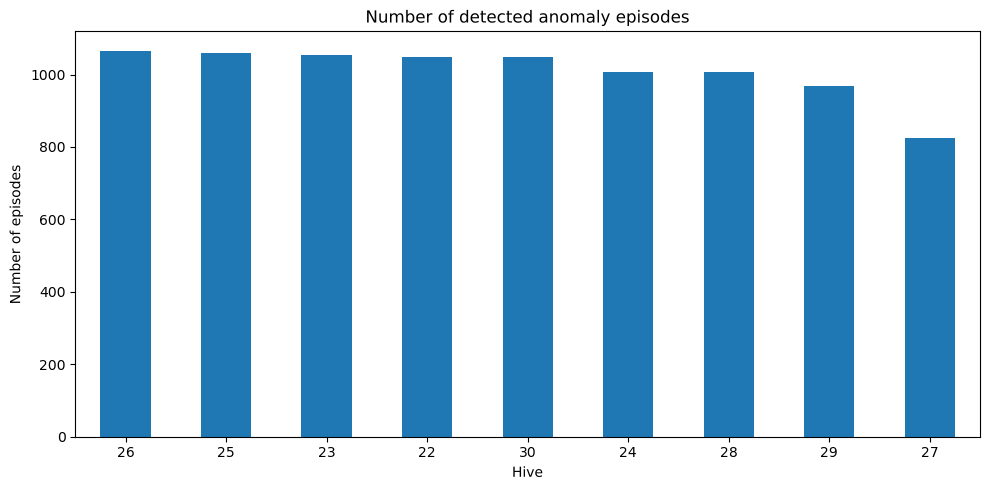

In [26]:
episodes_per_hive = (
    df_features
    .groupby("hive")["episode_id"]
    .nunique()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 5))
episodes_per_hive.plot(kind="bar")

plt.title("Number of detected anomaly episodes")
plt.xlabel("Hive")
plt.ylabel("Number of episodes")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

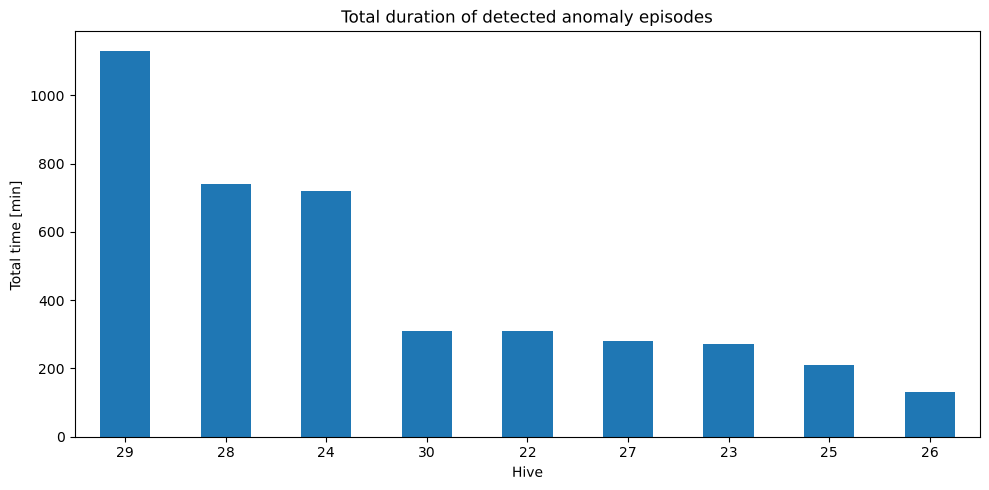

In [27]:
episode_duration = (
    df_features
    .groupby(["hive", "episode_id"])
    .agg(
        start=("timestamp", "min"),
        end=("timestamp", "max")
    )
)

episode_duration["duration_min"] = (
    episode_duration["end"] - episode_duration["start"]
).dt.total_seconds() / 60

total_duration = (
    episode_duration
    .groupby("hive")["duration_min"]
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 5))
total_duration.plot(kind="bar")

plt.title("Total duration of detected anomaly episodes")
plt.xlabel("Hive")
plt.ylabel("Total time [min]")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

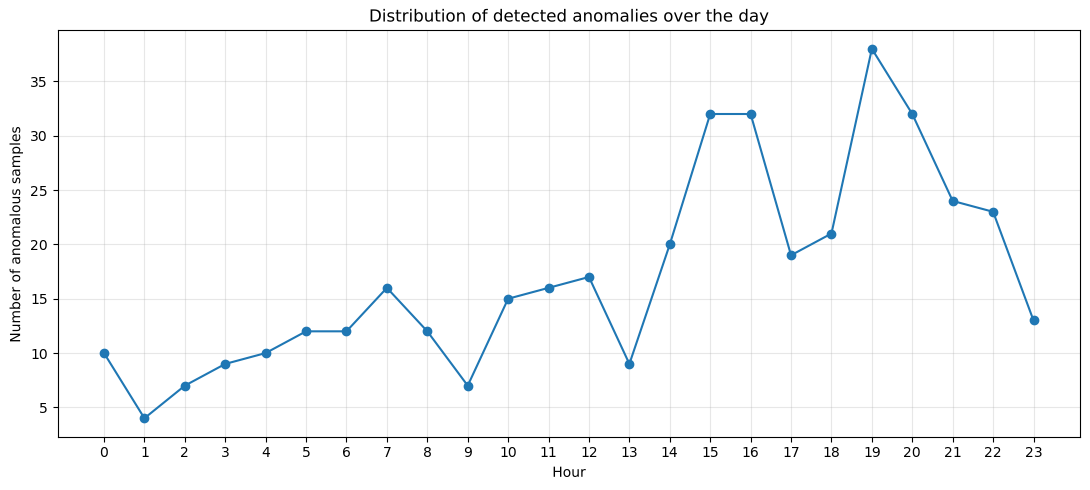

In [28]:
hourly_anomalies = (
    df_features[df_features["high_freq_anomaly"] == True]
    .groupby(df_features["hour_decimal"].astype(int))
    .size()
)

hourly_anomalies = hourly_anomalies.reindex(range(24), fill_value=0)

plt.figure(figsize=(11, 5))

plt.plot(
    hourly_anomalies.index,
    hourly_anomalies.values,
    marker="o"
)

plt.title("Distribution of detected anomalies over the day")
plt.xlabel("Hour")
plt.ylabel("Number of anomalous samples")
plt.xticks(range(24))
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

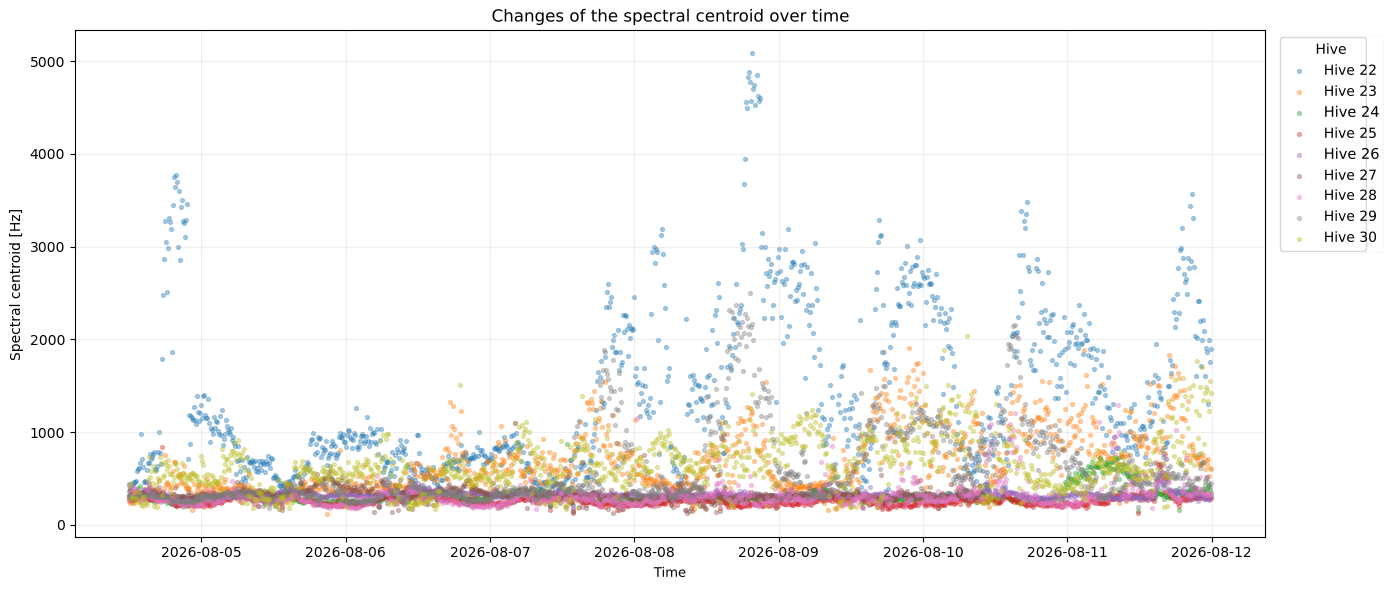

In [29]:
plt.figure(figsize=(14, 6))

for hive in sorted(df_features["hive"].unique()):

    hive_data = df_features[df_features["hive"] == hive]

    plt.scatter(
        hive_data["timestamp"],
        hive_data["spectral_centroid"],
        s=8,
        alpha=0.35,
        label=f"Hive {hive}"
    )

plt.title("Changes of the spectral centroid over time")
plt.xlabel("Time")
plt.ylabel("Spectral centroid [Hz]")

plt.legend(
    title="Hive",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

## Loudness and spectrum anomalies

In [30]:
df_features["hour"] = df_features["timestamp"].dt.hour

hour_profile = (
    df_features
    .groupby("hour")
    .agg(
        rms_mean=("rms_dbfs", "mean"),
        rms_std=("rms_dbfs", "std"),
        centroid_mean=("spectral_centroid", "mean"),
        centroid_std=("spectral_centroid", "std")
    )
)

print(hour_profile.round(4))

      rms_mean  rms_std  centroid_mean  centroid_std
hour                                                
0     -28.6962   3.7693       546.8427      509.0789
1     -28.7782   3.7923       536.5387      492.0014
2     -28.9310   3.6720       539.8307      512.8908
3     -29.1162   3.6175       567.9488      536.9125
4     -28.8974   3.6543       562.8588      498.2981
5     -28.5819   3.6520       525.6896      409.6120
6     -27.6814   3.9283       482.5225      301.7247
7     -26.6823   4.0263       454.5283      236.5105
8     -25.7363   4.5457       452.4800      261.8529
9     -24.7537   4.5912       428.6145      245.4617
10    -23.8557   5.5673       448.5378      266.0682
11    -23.4861   5.2483       441.4402      250.0285
12    -23.3190   5.2146       454.4892      276.9026
13    -23.4478   5.1614       477.4101      332.9799
14    -24.0636   4.8002       511.9290      354.4569
15    -25.0280   4.3279       571.6203      438.7838
16    -25.5461   4.8453       588.9656      57

In [31]:
audio = df_features.merge(
    hour_profile,
    left_on="hour",
    right_index=True,
    suffixes=("", "_hour")
)

audio["rms_zscore"] = (
    (audio["rms_dbfs"] - audio["rms_mean"])
    / audio["rms_std"]
)

audio["centroid_zscore"] = (
    (audio["spectral_centroid"] - audio["centroid_mean"])
    / audio["centroid_std"]
)

audio["anomaly_candidate"] = (
    (audio["rms_zscore"].abs() >= 3) |
    (audio["centroid_zscore"].abs() >= 3)
)

print(
    audio["anomaly_candidate"]
    .value_counts()
)

anomaly_candidate
False    9142
True      348
Name: count, dtype: int64


In [32]:
anomalies = (
    audio[audio["anomaly_candidate"]]
    .sort_values("timestamp")
)

print(
    anomalies[
        [
            "hive",
            "filename",
            "timestamp",
            "hour",
            "rms_dbfs",
            "spectral_centroid",
            "rms_zscore",
            "centroid_zscore"
        ]
    ].head(100).to_string(index=False)
)

 hive                        filename           timestamp  hour   rms_dbfs  spectral_centroid  rms_zscore  centroid_zscore
   30 2026-08-04_12-09-10_13.824s.wav 2026-08-04 12:09:10    12  -5.138252         279.699907    3.486476        -0.631230
   30 2026-08-04_12-29-11_14.592s.wav 2026-08-04 12:29:11    12  -7.303713         307.475586    3.071211        -0.530922
   30 2026-08-04_13-49-14_14.592s.wav 2026-08-04 13:49:14    13  -5.956388         244.118773    3.388878        -0.700617
   30 2026-08-04_13-59-14_14.592s.wav 2026-08-04 13:59:14    13  -4.722332         210.640884    3.627970        -0.801157
   30 2026-08-04_14-19-15_14.592s.wav 2026-08-04 14:19:15    14  -3.042091         206.869061    4.379309        -0.860641
   30 2026-08-04_14-29-15_13.824s.wav 2026-08-04 14:29:15    14  -6.248268         303.582660    3.711381        -0.587790
   30 2026-08-04_14-39-16_14.592s.wav 2026-08-04 14:39:16    14  -8.641196         236.109801    3.212874        -0.778146
   30 2026-08-04

In [33]:
anomalies_by_hive = (
    audio
    .groupby("hive")["anomaly_candidate"]
    .agg(
        anomalies="sum",
        recordings="count"
    )
)

anomalies_by_hive["anomaly_percent"] = (
    anomalies_by_hive["anomalies"]
    / anomalies_by_hive["recordings"]
    * 100
)

print(anomalies_by_hive.round(2))

      anomalies  recordings  anomaly_percent
hive                                        
22          238        1080            22.04
23           12        1080             1.11
24            0        1079             0.00
25            1        1080             0.09
26            2        1079             0.19
27           12         852             1.41
28            2        1080             0.19
29           14        1080             1.30
30           67        1080             6.20


In [34]:
anomalies_by_hour = (
    audio[audio["anomaly_candidate"]]
    .groupby("hour")
    .size()
)

print(anomalies_by_hour)

hour
0     15
1     16
2     15
3     14
4     14
5     11
6     10
7     11
8     13
9     14
10    15
11    16
12    20
13    13
14    21
15    16
16    23
17    12
18    13
19    14
20    13
21    13
22    13
23    13
dtype: int64


In [35]:
anomalies_by_date = (
    audio[audio["anomaly_candidate"]]
    .groupby(["hive", "date"])
    .size()
    .reset_index(name="anomalies")
)

print(anomalies_by_date.to_string(index=False))

 hive       date  anomalies
   22 2026-08-04         21
   22 2026-08-07          2
   22 2026-08-08         75
   22 2026-08-09         73
   22 2026-08-10         42
   22 2026-08-11         25
   23 2026-08-04          1
   23 2026-08-05          1
   23 2026-08-08          1
   23 2026-08-10          6
   23 2026-08-11          3
   25 2026-08-04          1
   26 2026-08-09          2
   27 2026-08-05          2
   27 2026-08-06          5
   27 2026-08-07          2
   27 2026-08-08          3
   28 2026-08-05          1
   28 2026-08-11          1
   29 2026-08-08          4
   29 2026-08-10         10
   30 2026-08-04         12
   30 2026-08-05         16
   30 2026-08-06         13
   30 2026-08-07          2
   30 2026-08-09         10
   30 2026-08-10         12
   30 2026-08-11          2


### Anomaly visualization

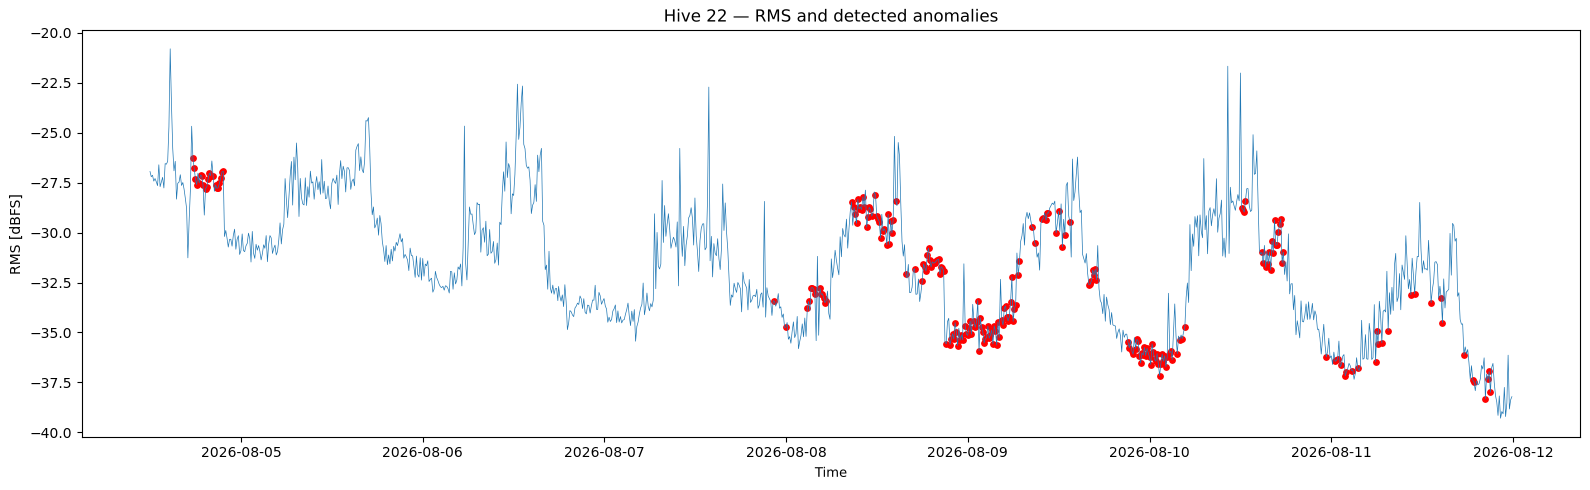

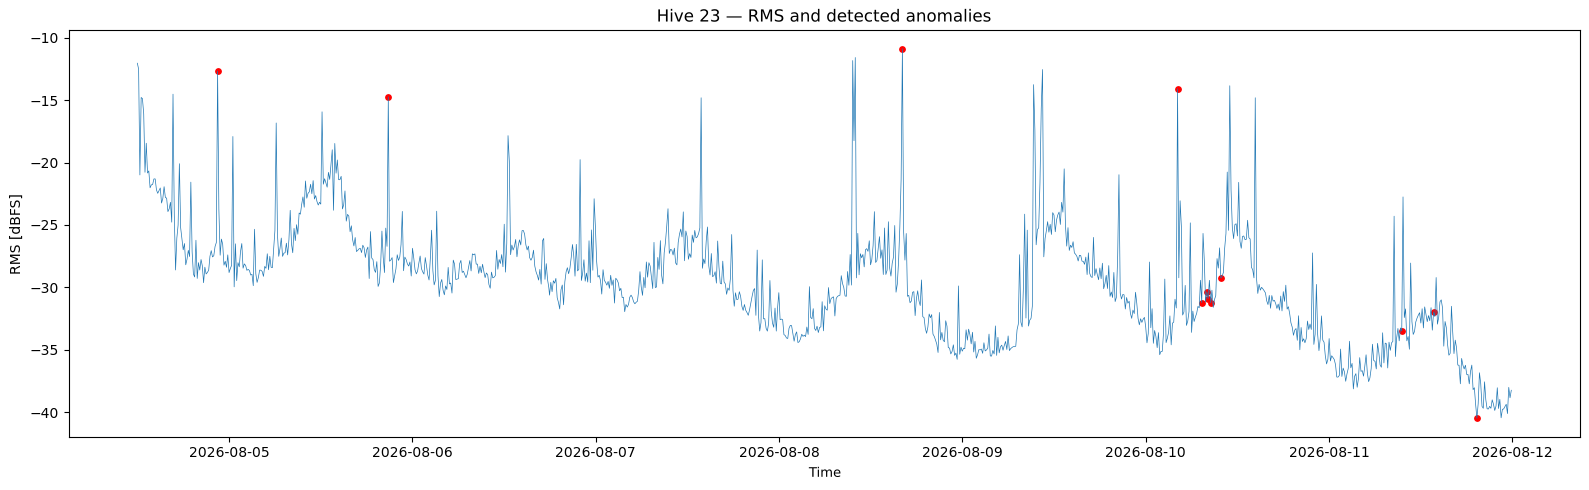

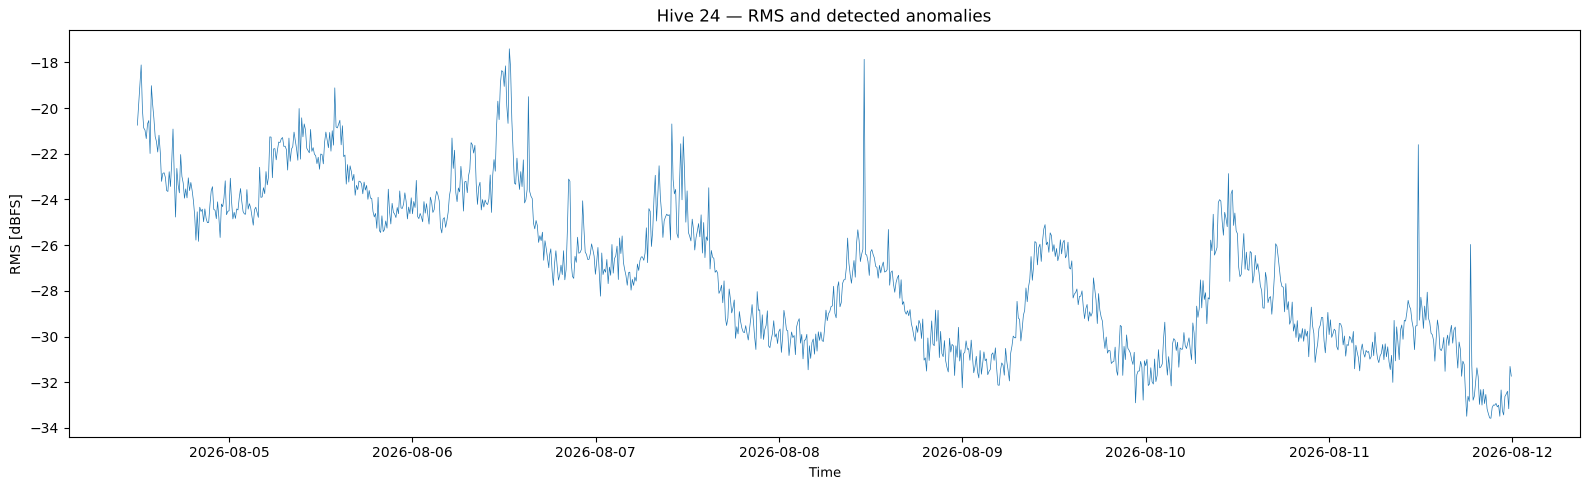

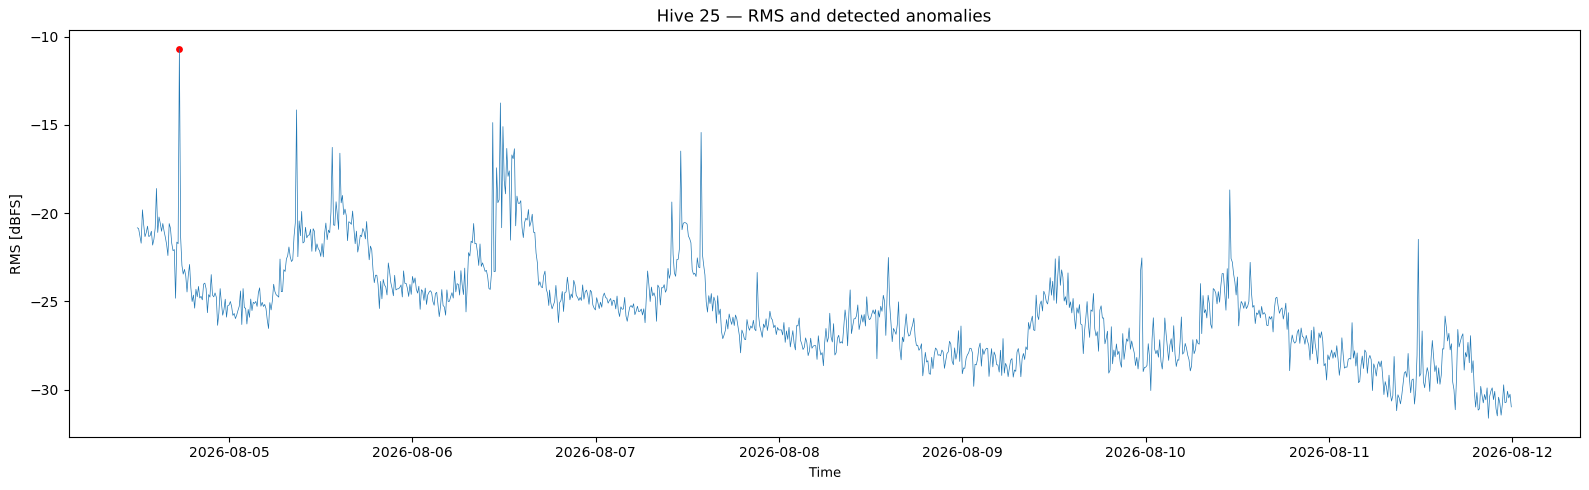

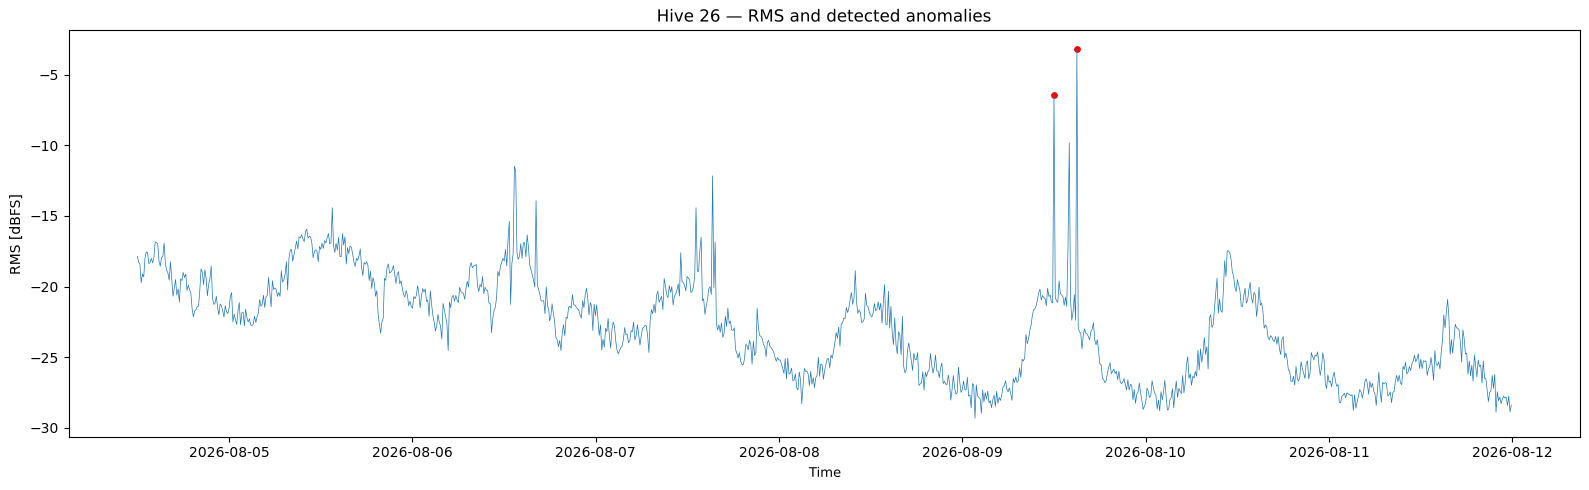

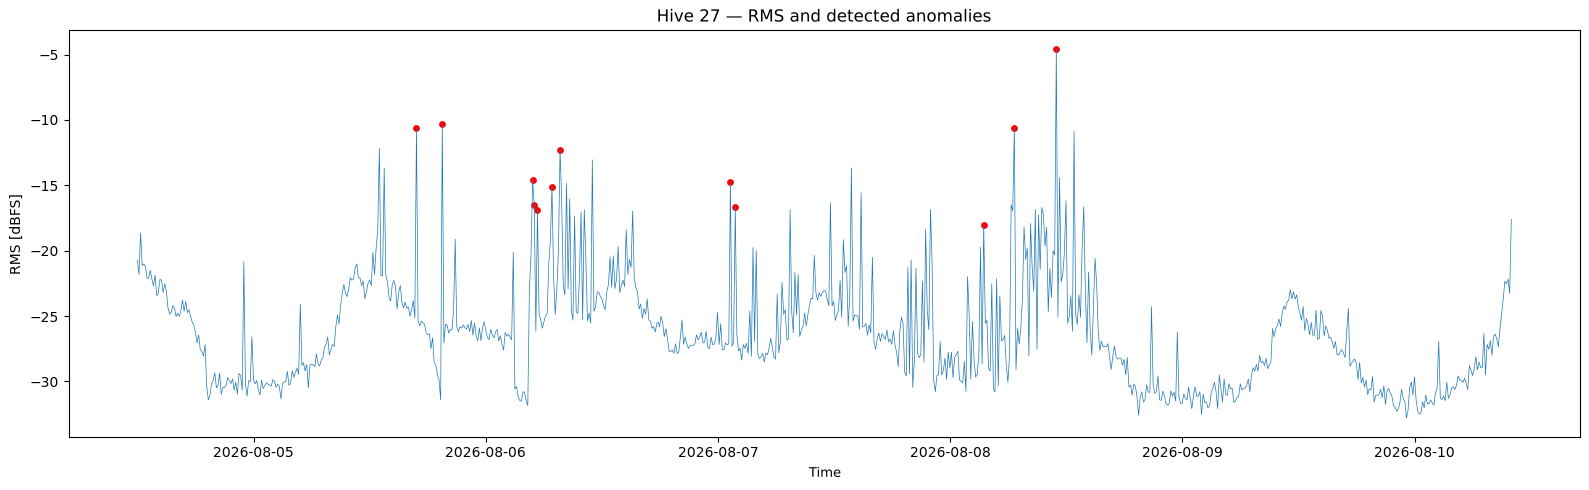

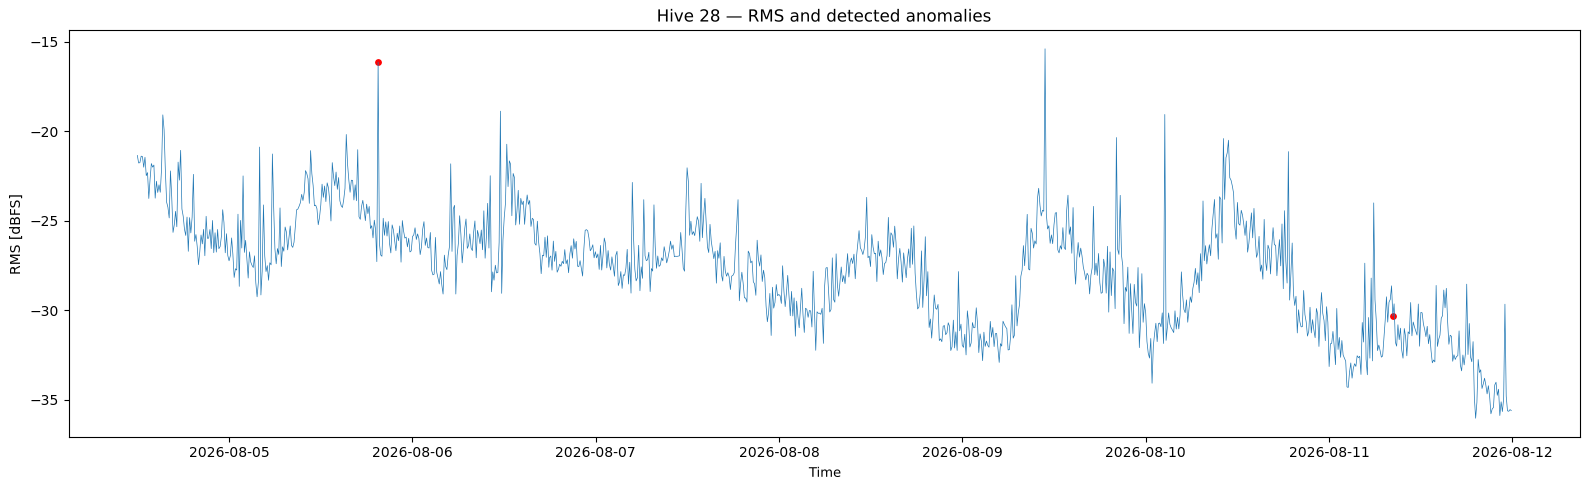

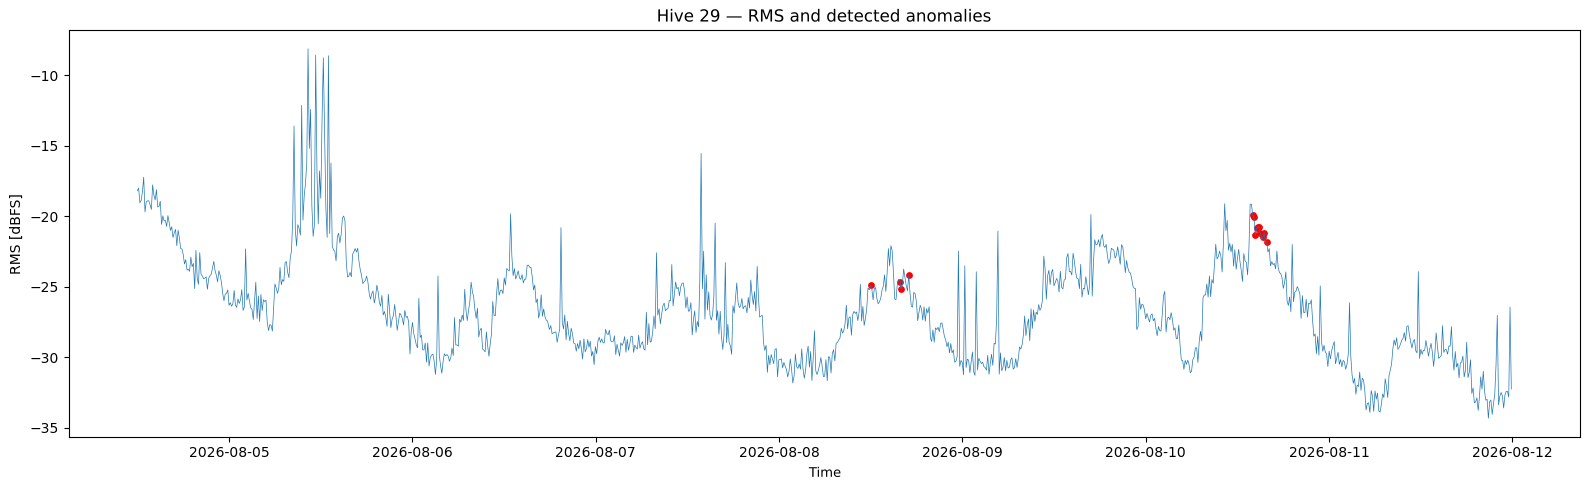

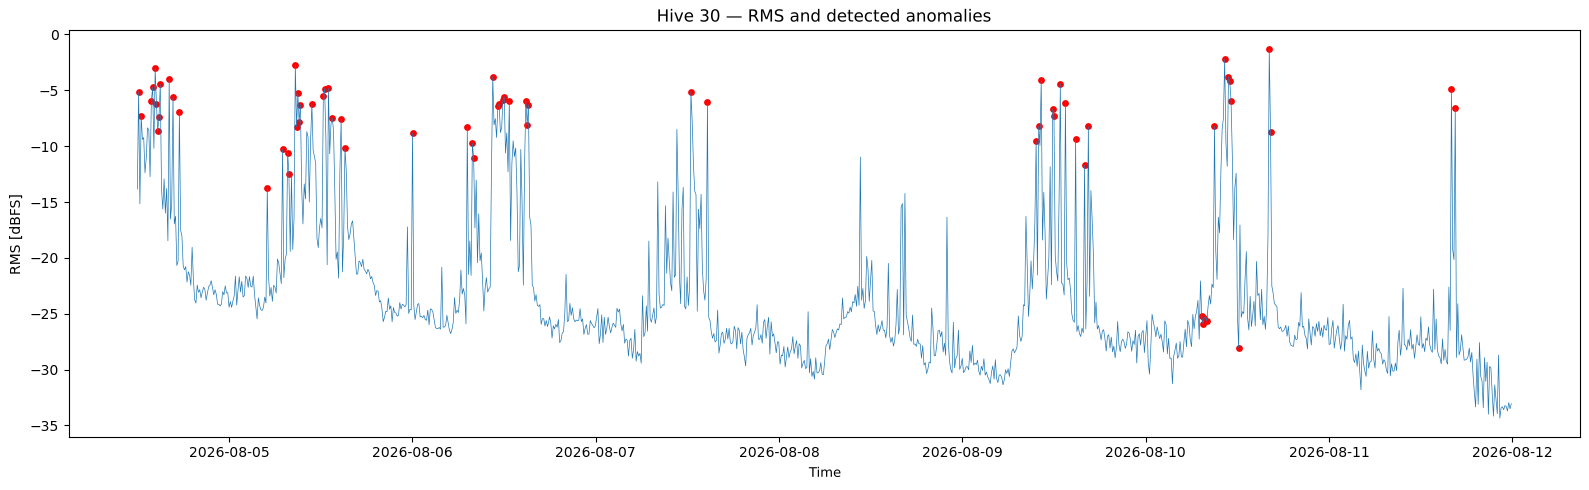

In [36]:
for hive in sorted(audio["hive"].unique()):
    hive_data = audio[
        audio["hive"] == hive
    ].sort_values("timestamp")

    plt.figure(figsize=(16, 5))

    plt.plot(
        hive_data["timestamp"],
        hive_data["rms_dbfs"],
        linewidth=0.5
    )

    anomalies_hive = hive_data[hive_data["anomaly_candidate"]]

    plt.scatter(
        anomalies_hive["timestamp"],
        anomalies_hive["rms_dbfs"],
        s=15,
        color="red"
    )

    plt.title(f"Hive {hive} — RMS and detected anomalies")
    plt.xlabel("Time")
    plt.ylabel("RMS [dBFS]")
    plt.tight_layout()
    plt.show()

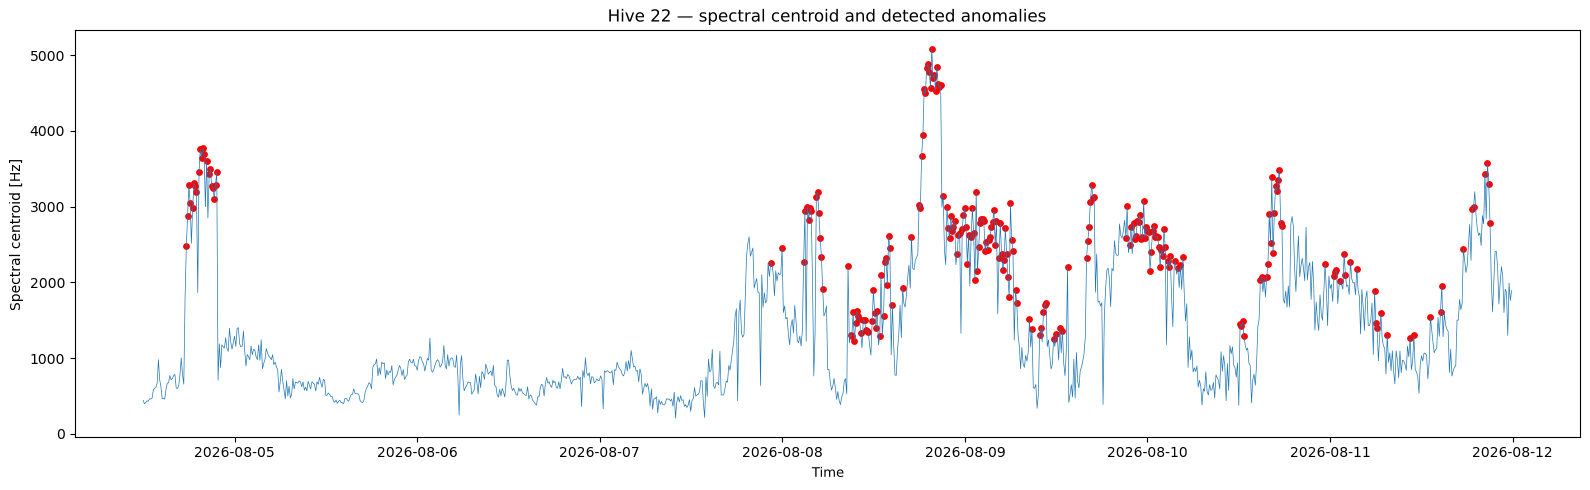

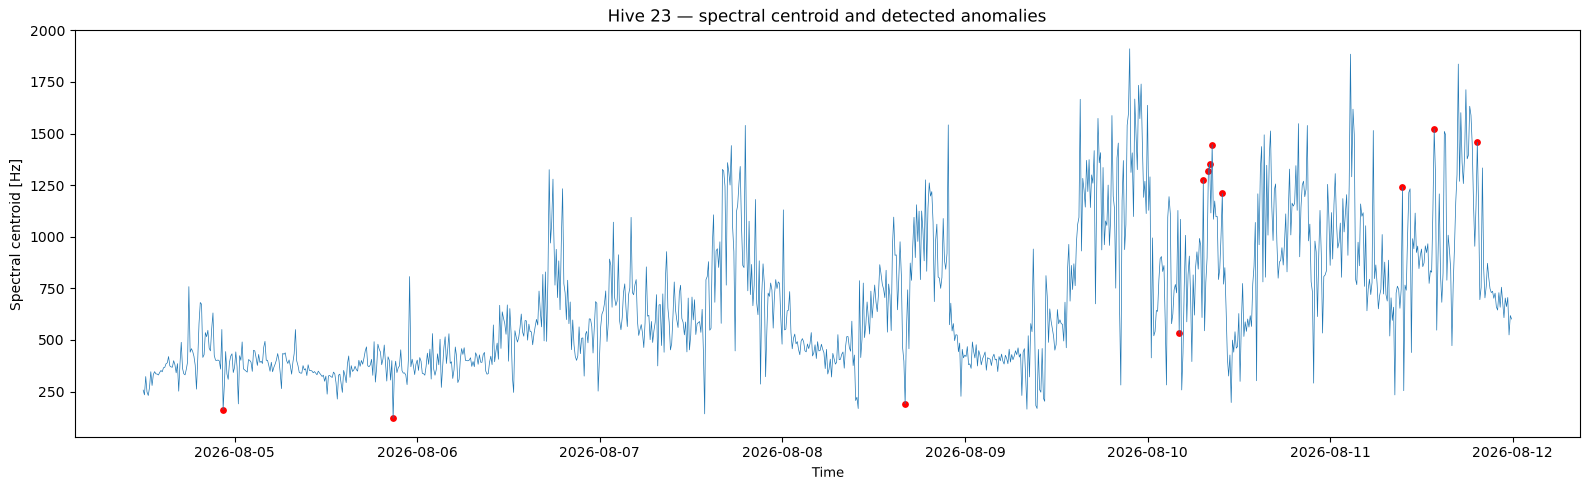

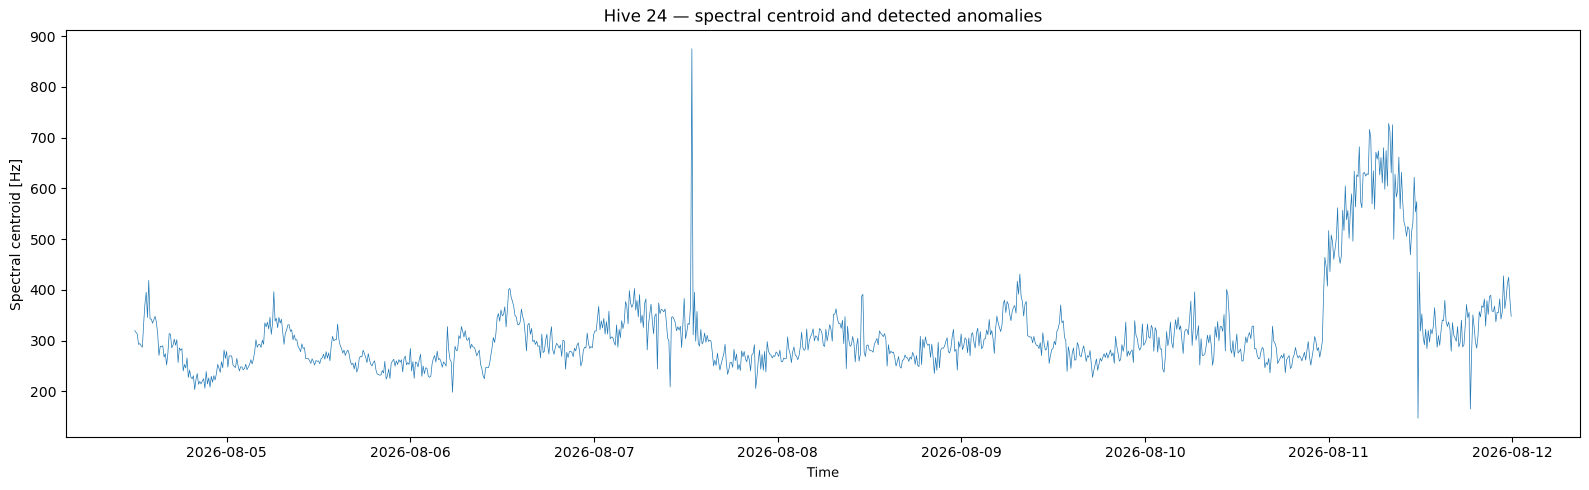

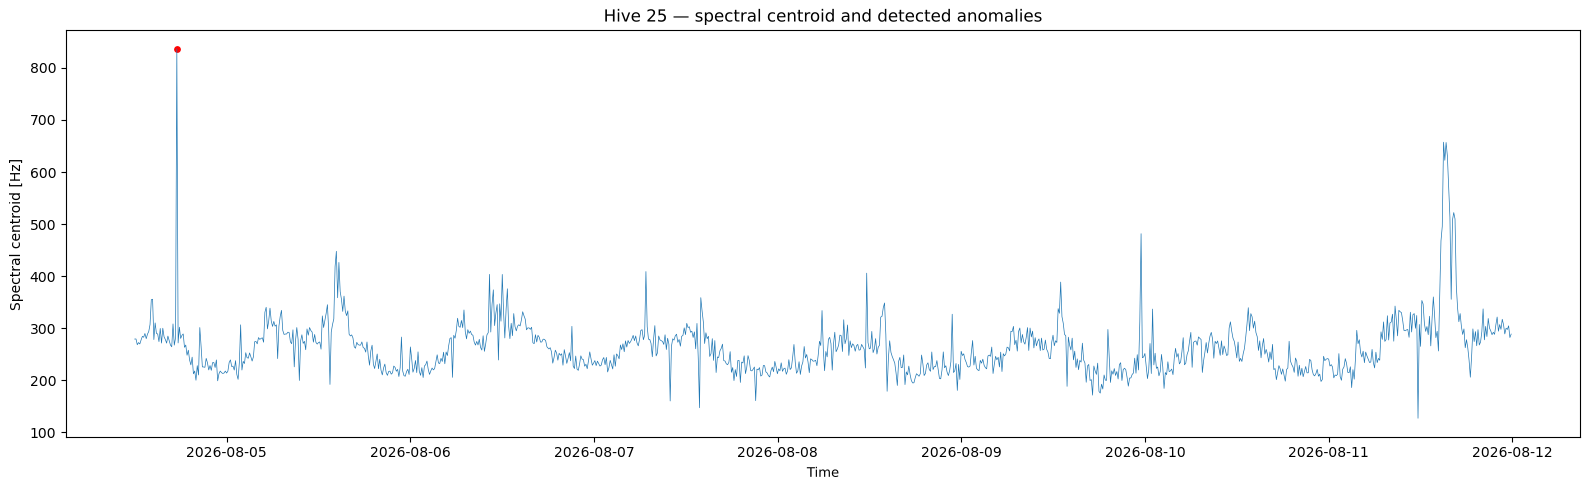

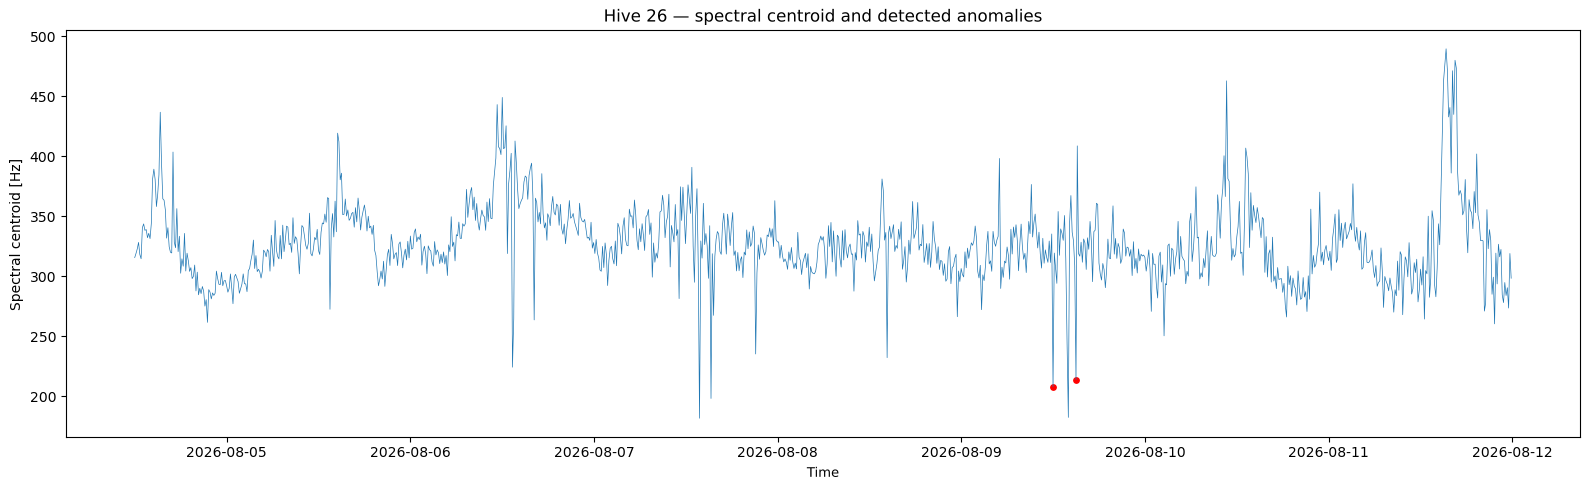

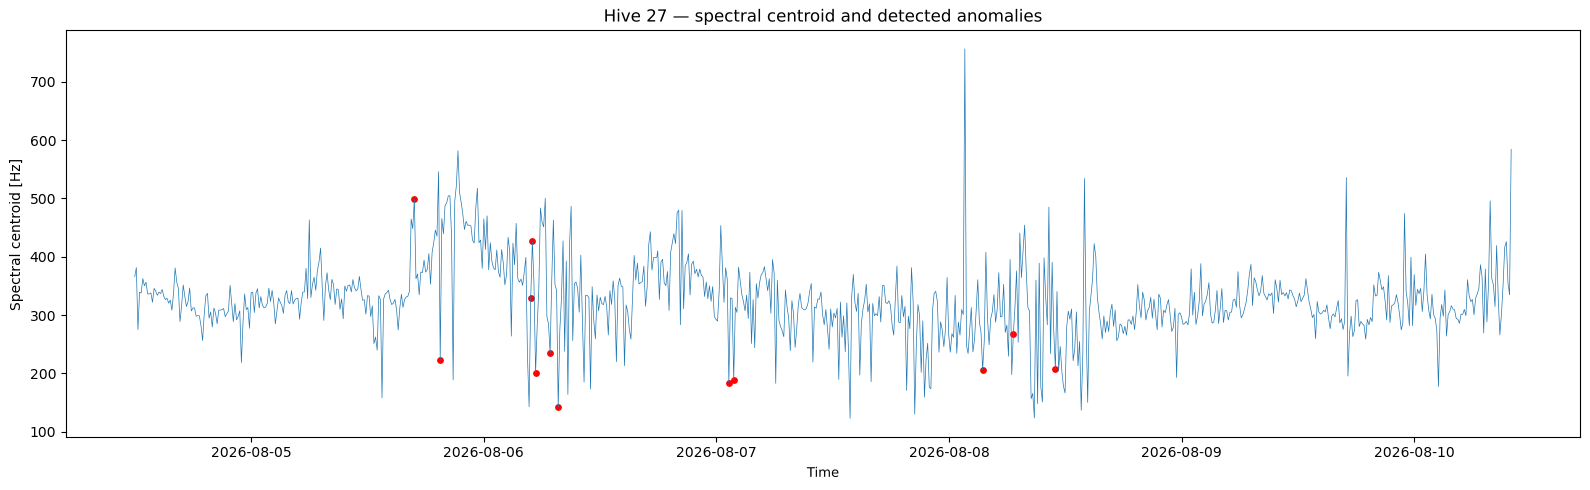

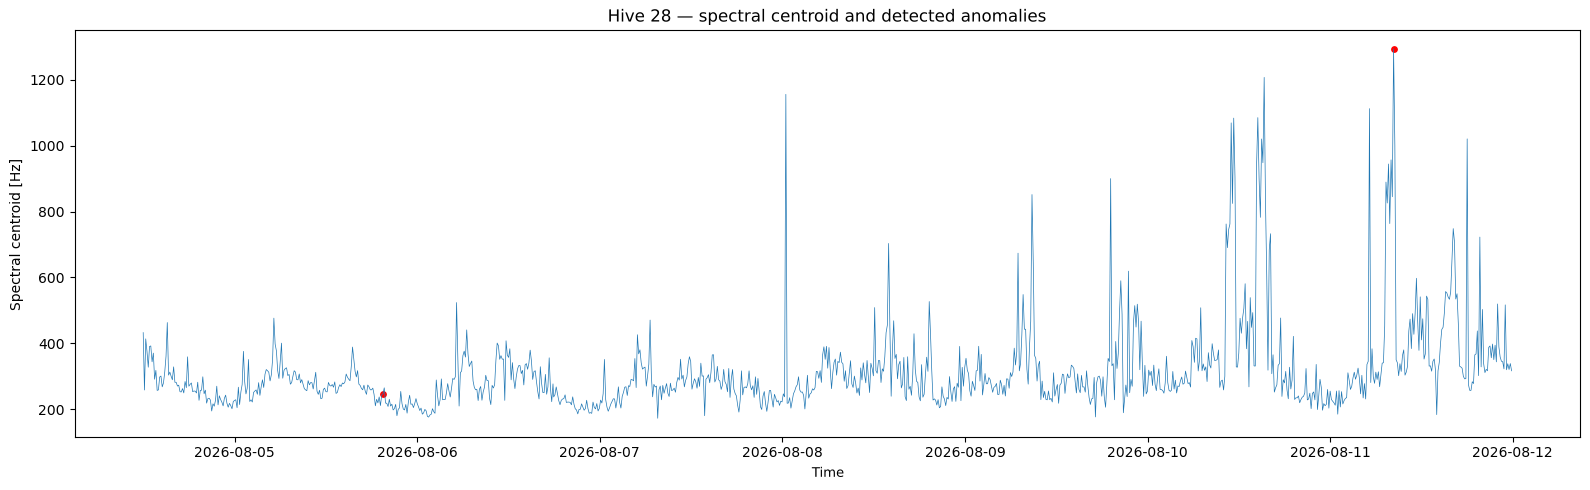

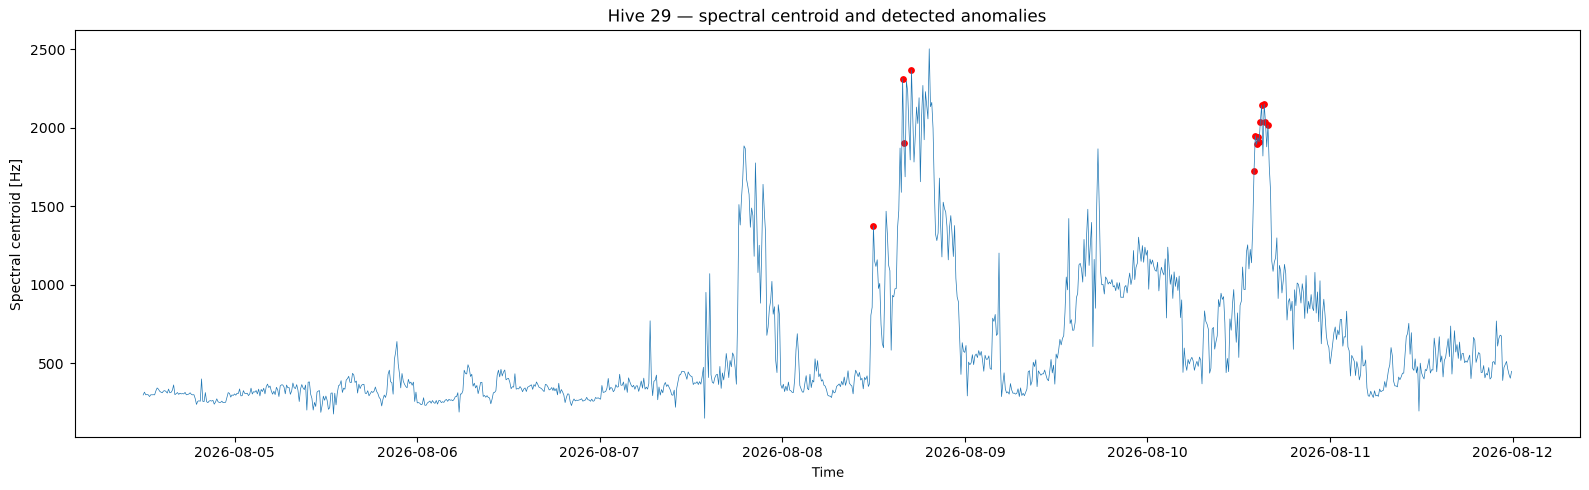

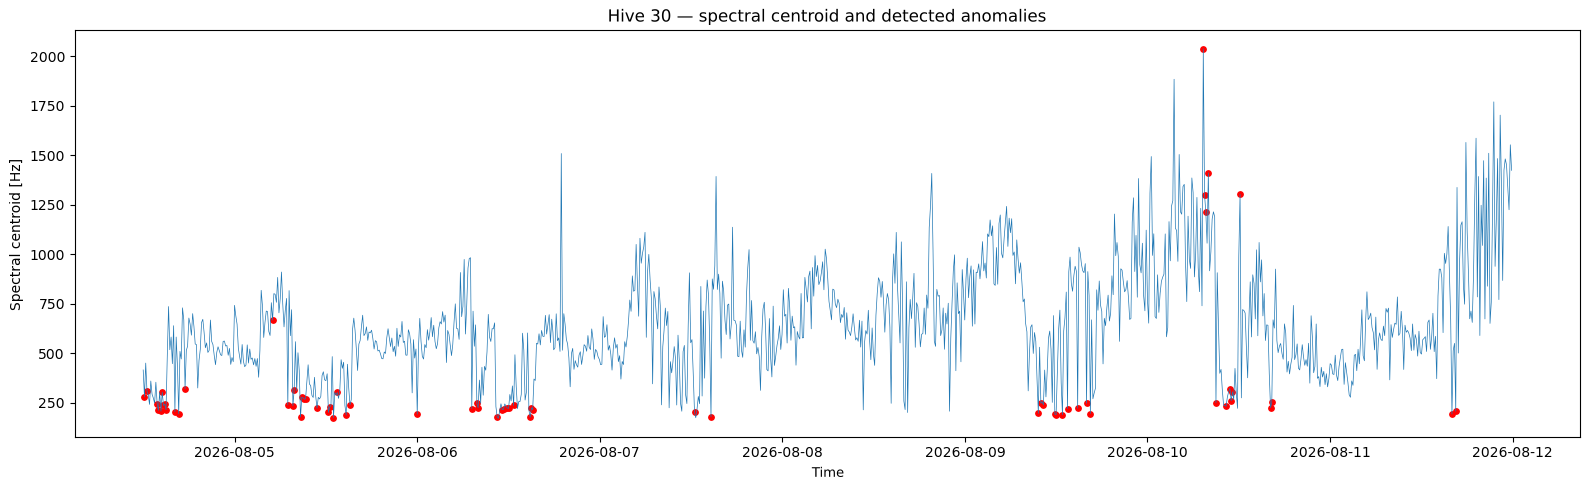

In [37]:
for hive in sorted(audio["hive"].unique()):
    hive_data = audio[
        audio["hive"] == hive
    ].sort_values("timestamp")

    plt.figure(figsize=(16, 5))

    plt.plot(
        hive_data["timestamp"],
        hive_data["spectral_centroid"],
        linewidth=0.5
    )

    anomalies_hive = hive_data[hive_data["anomaly_candidate"]]

    plt.scatter(
        anomalies_hive["timestamp"],
        anomalies_hive["spectral_centroid"],
        s=15,
        color="red"
    )

    plt.title(f"Hive {hive} — spectral centroid and detected anomalies")
    plt.xlabel("Time")
    plt.ylabel("Spectral centroid [Hz]")
    plt.tight_layout()
    plt.show()

### Grouping anomalies into events

In [38]:
anomalies = (
    audio[audio["anomaly_candidate"]]
    .copy()
    .sort_values(["hive", "timestamp"])
)

anomalies["time_diff"] = (
    anomalies
    .groupby("hive")["timestamp"]
    .diff()
    .dt.total_seconds()
    / 60
)

anomalies["event"] = (
    anomalies["time_diff"].isna()
    | (anomalies["time_diff"] > 5)
)

anomalies["event_id"] = (
    anomalies
    .groupby("hive")["event"]
    .cumsum()
)

events = (
    anomalies
    .groupby(["hive", "event_id"])
    .agg(
        start=("timestamp", "min"),
        end=("timestamp", "max"),
        recordings=("filename", "count"),
        rms_mean=("rms_dbfs", "mean"),
        rms_max=("rms_dbfs", "max"),
        centroid_mean=("spectral_centroid", "mean"),
        centroid_min=("spectral_centroid", "min"),
        centroid_max=("spectral_centroid", "max")
    )
    .reset_index()
)

events["duration_min"] = (
    events["end"] - events["start"]
).dt.total_seconds() / 60

events = events.sort_values(
    ["hive", "start"]
)

print(events.to_string(index=False))

 hive  event_id               start                 end  recordings   rms_mean    rms_max  centroid_mean  centroid_min  centroid_max  duration_min
   22         1 2026-08-04 17:39:15 2026-08-04 17:39:15           1 -26.295318 -26.295318    2473.818725   2473.818725   2473.818725           0.0
   22         2 2026-08-04 17:49:15 2026-08-04 17:49:15           1 -26.781282 -26.781282    2870.164704   2870.164704   2870.164704           0.0
   22         3 2026-08-04 17:59:15 2026-08-04 17:59:15           1 -27.331607 -27.331607    3280.126552   3280.126552   3280.126552           0.0
   22         4 2026-08-04 18:09:16 2026-08-04 18:09:16           1 -27.611029 -27.611029    3052.767814   3052.767814   3052.767814           0.0
   22         5 2026-08-04 18:29:17 2026-08-04 18:29:17           1 -27.517777 -27.517777    2986.936251   2986.936251   2986.936251           0.0
   22         6 2026-08-04 18:39:17 2026-08-04 18:39:17           1 -27.121533 -27.121533    3312.457923   3312.457923

### Summary of events for each hive

In [39]:
event_summary = (
    events
    .groupby("hive")
    .agg(
        events=("event_id", "count"),
        recordings_mean=("recordings", "mean"),
        recordings_max=("recordings", "max"),
        rms_mean=("rms_mean", "mean"),
        rms_max=("rms_max", "max"),
        centroid_mean=("centroid_mean", "mean"),
        duration_mean=("duration_min", "mean"),
        duration_max=("duration_min", "max")
    )
    .round(3)
)

print(event_summary)

      events  recordings_mean  recordings_max  rms_mean  rms_max  \
hive                                                               
22       238              1.0               1   -32.681  -26.295   
23        12              1.0               1   -25.939  -10.896   
25         1              1.0               1   -10.690  -10.690   
26         2              1.0               1    -4.799   -3.179   
27        12              1.0               1   -13.409   -4.558   
28         2              1.0               1   -23.232  -16.131   
29        14              1.0               1   -22.016  -19.914   
30        67              1.0               1    -8.184   -1.283   

      centroid_mean  duration_mean  duration_max  
hive                                              
22         2573.523            0.0           0.0  
23          985.541            0.0           0.0  
25          836.704            0.0           0.0  
26          210.759            0.0           0.0  
27          2

### Longest and strongest events

In [40]:
longest_events = events.sort_values("duration_min", ascending=False)

print("Longest events:")
print(
    longest_events[
        [
            "hive",
            "event_id",
            "start",
            "end",
            "recordings",
            "rms_mean",
            "rms_max",
            "duration_min"
        ]
    ].head(15).to_string(index=False)
)

strongest_events = events.sort_values("rms_max", ascending=False)

print("\nStrongest events by RMS:")
print(
    strongest_events[
        [
            "hive",
            "event_id",
            "start",
            "end",
            "recordings",
            "rms_mean",
            "rms_max",
            "duration_min"
        ]
    ].head(15).to_string(index=False)
)

Longest events:
 hive  event_id               start                 end  recordings   rms_mean    rms_max  duration_min
   22         1 2026-08-04 17:39:15 2026-08-04 17:39:15           1 -26.295318 -26.295318           0.0
   22         2 2026-08-04 17:49:15 2026-08-04 17:49:15           1 -26.781282 -26.781282           0.0
   22         3 2026-08-04 17:59:15 2026-08-04 17:59:15           1 -27.331607 -27.331607           0.0
   22         4 2026-08-04 18:09:16 2026-08-04 18:09:16           1 -27.611029 -27.611029           0.0
   22         5 2026-08-04 18:29:17 2026-08-04 18:29:17           1 -27.517777 -27.517777           0.0
   22         6 2026-08-04 18:39:17 2026-08-04 18:39:17           1 -27.121533 -27.121533           0.0
   22         7 2026-08-04 18:49:17 2026-08-04 18:49:17           1 -27.174003 -27.174003           0.0
   22         8 2026-08-04 18:59:18 2026-08-04 18:59:18           1 -27.626653 -27.626653           0.0
   22         9 2026-08-04 19:19:18 2026-08-04 1

### MAD + percentile threshold per hive

instead of the z-score threshold, it computes the deviation from the median per hive (MAD of rms_dbfs_z and spectral_centroid_z) and takes the top 1% of recordings per hive as anomaly candidates

In [42]:
anomaly_data = df_features.copy()

anomaly_data["anomaly_score"] = anomaly_data[
    ["rms_dbfs_z", "spectral_centroid_z"]
].abs().max(axis=1)

share_limit = 0.01
score_thresholds = (
    anomaly_data
    .groupby("hive")["anomaly_score"]
    .transform(lambda values: values.quantile(1 - share_limit))
)

anomaly_data["score_threshold"] = score_thresholds
anomaly_data["anomaly_candidate_mad"] = (
    anomaly_data["anomaly_score"] >= anomaly_data["score_threshold"]
)

threshold_table = pd.DataFrame({
    "threshold": [3, 3.5, 4, 4.5, 5],
    "recordings": [
        (anomaly_data["anomaly_score"] >= t).sum()
        for t in [3, 3.5, 4, 4.5, 5]
    ]
})
threshold_table["percent"] = (
    threshold_table["recordings"] / len(anomaly_data) * 100
).round(3)

print(threshold_table)

anomalies_final = anomaly_data[
    anomaly_data["anomaly_candidate_mad"]
].copy()

print({len(anomalies_final)})

   threshold  recordings  percent
0        3.0         782    8.240
1        3.5         577    6.080
2        4.0         429    4.521
3        4.5         331    3.488
4        5.0         260    2.740
{97}


In [43]:
anomalies_final = anomalies_final.sort_values(["hive", "timestamp"])

anomalies_final["gap_min"] = (
    anomalies_final.groupby("hive")["timestamp"]
    .diff().dt.total_seconds().div(60)
)
anomalies_final["new_event"] = (
    anomalies_final["gap_min"].isna()
    | (anomalies_final["gap_min"] > 5)
)
anomalies_final["event_id"] = (
    anomalies_final.groupby("hive")["new_event"].cumsum()
)

events_final = (
    anomalies_final.groupby(["hive", "event_id"], as_index=False)
    .agg(
        start=("timestamp", "min"),
        end=("timestamp", "max"),
        recordings=("filename", "count"),
        rms_mean=("rms_dbfs", "mean"),
        rms_max=("rms_dbfs", "max"),
        centroid_mean=("spectral_centroid", "mean"),
        max_anomaly_score=("anomaly_score", "max")
    )
)
events_final["duration_min"] = (
    events_final["end"] - events_final["start"]
).dt.total_seconds().div(60)

event_summary_final = (
    events_final.groupby("hive", as_index=False)
    .agg(
        events=("event_id", "count"),
        anomaly_recordings=("recordings", "sum"),
        longest_event_min=("duration_min", "max"),
        mean_rms=("rms_mean", "mean"),
        mean_centroid=("centroid_mean", "mean")
    )
    .sort_values("events", ascending=False)
)

print(f"Number of events: {len(events_final)}")
print(event_summary_final.to_string(index=False))

Number of events: 97
 hive  events  anomaly_recordings  longest_event_min   mean_rms  mean_centroid
   22      11                  11                0.0 -31.629585    4747.098704
   23      11                  11                0.0 -19.901603     799.286935
   24      11                  11                0.0 -30.618653     712.449547
   25      11                  11                0.0 -26.439018     592.980195
   26      11                  11                0.0 -19.445437     395.508575
   28      11                  11                0.0 -27.698054    1090.876188
   29      11                  11                0.0 -24.754359    2259.559984
   30      11                  11                0.0  -5.329445     388.313446
   27       9                   9                0.0 -21.095659     443.469617


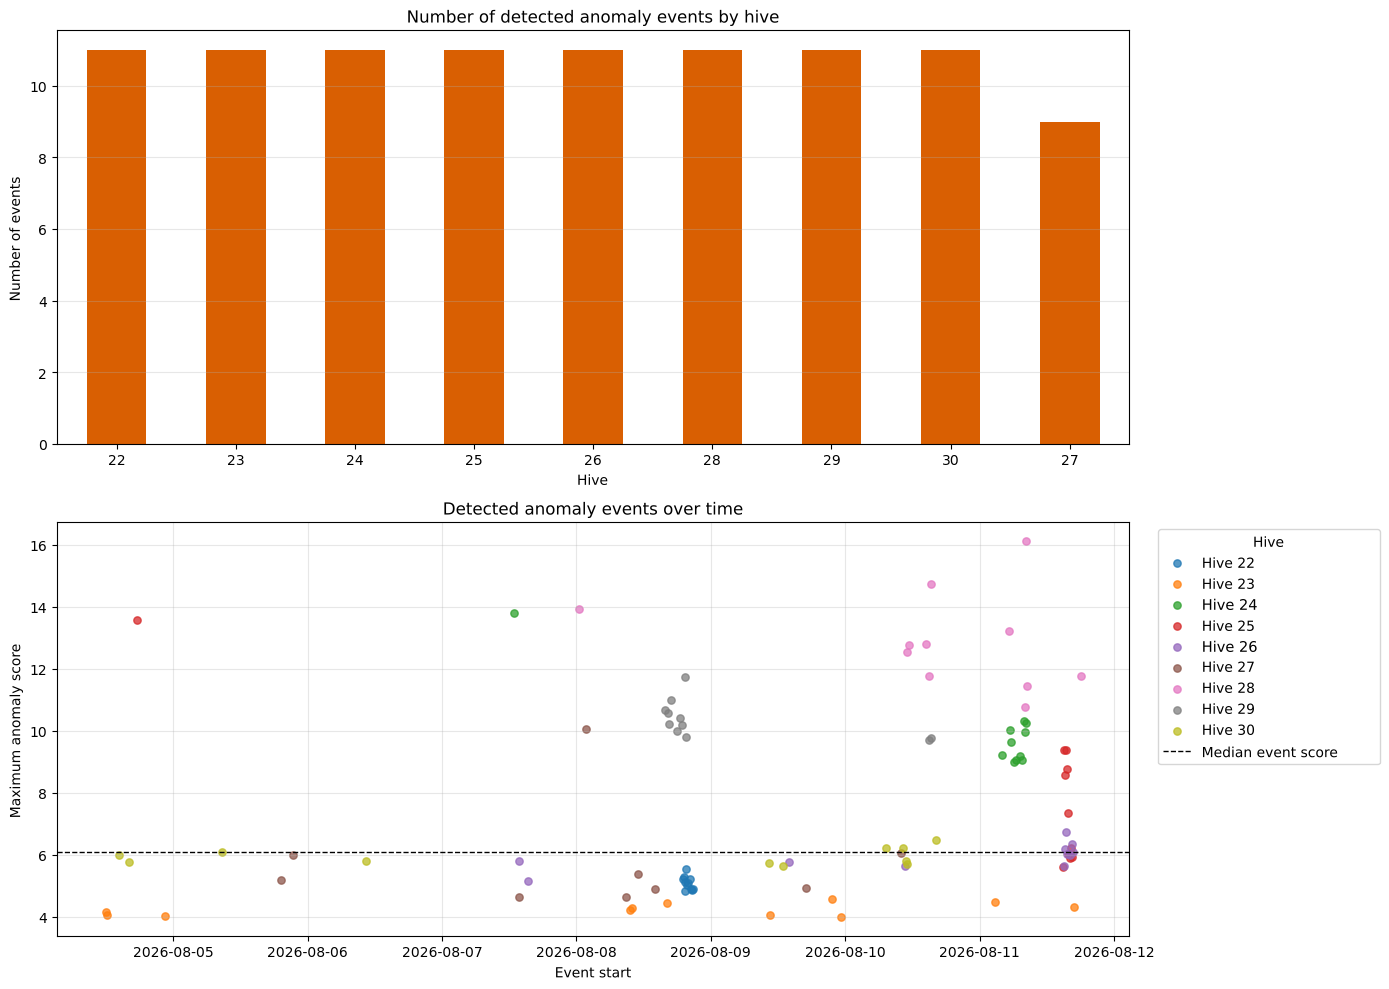

In [44]:
if events_final.empty:
    print("No events to visualise.")
else:
    figure, axes = plt.subplots(2, 1, figsize=(14, 10))

    event_counts = (
        events_final.groupby("hive")
        .size()
        .sort_values(ascending=False)
    )
    event_counts.plot(kind="bar", ax=axes[0], color="#d95f02")
    axes[0].set_title("Number of detected anomaly events by hive")
    axes[0].set_xlabel("Hive")
    axes[0].set_ylabel("Number of events")
    axes[0].tick_params(axis="x", rotation=0)
    axes[0].grid(axis="y", alpha=0.3)

    for hive, hive_events in events_final.groupby("hive"):
        axes[1].scatter(
            hive_events["start"],
            hive_events["max_anomaly_score"],
            s=28,
            alpha=0.75,
            label=f"Hive {hive}"
        )

    axes[1].axhline(
        events_final["max_anomaly_score"].median(),
        color="black",
        linestyle="--",
        linewidth=1,
        label="Median event score"
    )
    axes[1].set_title("Detected anomaly events over time")
    axes[1].set_xlabel("Event start")
    axes[1].set_ylabel("Maximum anomaly score")
    axes[1].grid(alpha=0.3)
    axes[1].legend(title="Hive", bbox_to_anchor=(1.02, 1), loc="upper left")
    figure.tight_layout()
    plt.show()

 hive               start                 end  recordings  duration_min    rms_max  max_anomaly_score
   28 2026-08-11 08:20:48 2026-08-11 08:20:48           1           0.0 -30.333496          16.117993
   28 2026-08-10 15:20:09 2026-08-10 15:20:09           1           0.0 -28.274040          14.737689
   28 2026-08-08 00:27:43 2026-08-08 00:27:43           1           0.0 -27.520679          13.919163
   24 2026-08-07 12:47:40 2026-08-07 12:47:40           1           0.0 -25.312639          13.789782
   25 2026-08-04 17:29:12 2026-08-04 17:29:12           1           0.0 -10.690285          13.567027
   28 2026-08-11 05:10:41 2026-08-11 05:10:41           1           0.0 -30.412439          13.229525
   28 2026-08-10 14:30:07 2026-08-10 14:30:07           1           0.0 -27.051886          12.794524
   28 2026-08-10 11:19:59 2026-08-10 11:19:59           1           0.0 -23.054265          12.770918
   28 2026-08-10 10:59:59 2026-08-10 10:59:59           1           0.0 -22.598534

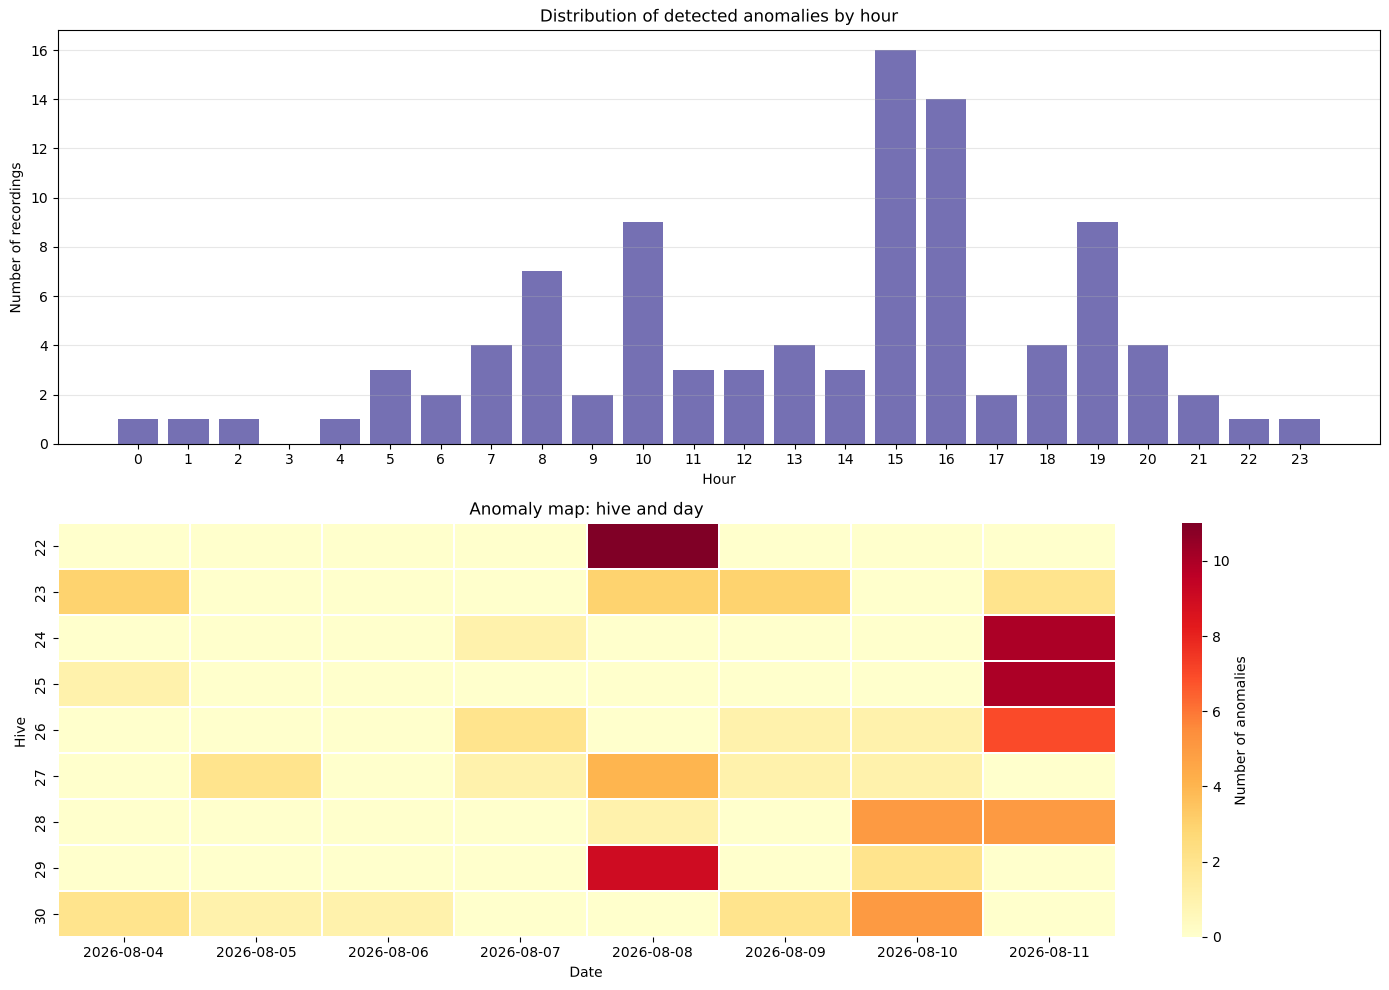

In [45]:
if events_final.empty:
    print("No events for further analysis.")
else:
    top_events = events_final.sort_values(
        "max_anomaly_score", ascending=False
    ).head(20)
    print(
        top_events[
            [
                "hive",
                "start",
                "end",
                "recordings",
                "duration_min",
                "rms_max",
                "max_anomaly_score"
            ]
        ].to_string(index=False)
    )

    anomalies_by_hour_final = (
        anomalies_final.groupby(anomalies_final["timestamp"].dt.hour)
        .size()
        .reindex(range(24), fill_value=0)
    )
    anomalies_by_day_hive = (
        anomalies_final.assign(
            date=anomalies_final["timestamp"].dt.date
        )
        .groupby(["date", "hive"])
        .size()
        .unstack(fill_value=0)
    )

    figure, axes = plt.subplots(2, 1, figsize=(14, 10))
    axes[0].bar(
        anomalies_by_hour_final.index,
        anomalies_by_hour_final.values,
        color="#7570b3"
    )
    axes[0].set_title("Distribution of detected anomalies by hour")
    axes[0].set_xlabel("Hour")
    axes[0].set_ylabel("Number of recordings")
    axes[0].set_xticks(range(24))
    axes[0].grid(axis="y", alpha=0.3)

    sns.heatmap(
        anomalies_by_day_hive.T,
        cmap="YlOrRd",
        linewidths=0.2,
        ax=axes[1],
        cbar_kws={"label": "Number of anomalies"}
    )
    axes[1].set_title("Anomaly map: hive and day")
    axes[1].set_xlabel("Date")
    axes[1].set_ylabel("Hive")
    figure.tight_layout()
    plt.show()